# CS180 Project 3: Flow Models

Part A explores a pretrained text-to-image flow model (PixNerd). Part B trains flow matching models from scratch on MNIST.

Convention throughout: $x_t=(1-t)\epsilon+t x_1$, so $t=0$ is pure noise and $t=1$ is a clean image.

# Part A: Exploring the Power of Flow Models

## 1.1 Constructing Noisy Training Inputs

One noise tensor $\epsilon$ is reused at $t=0.25, 0.50, 0.75$.

In [ ]:
def interpolate(image, noise, t):
    return (1-t)*noise + t*image

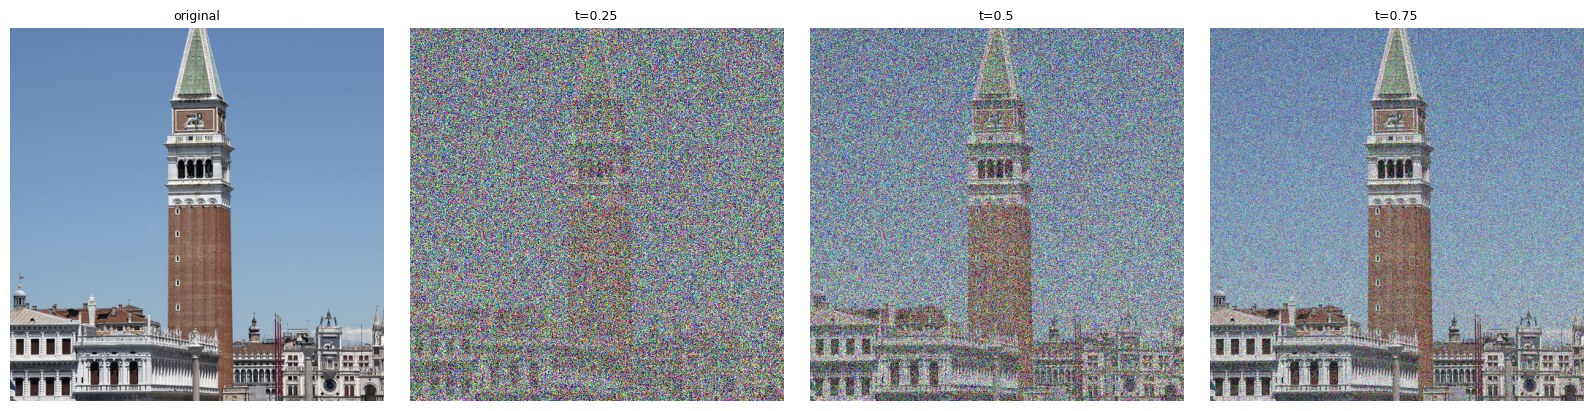

In [ ]:
# results

## 1.2 Classical Denoising

Each noisy input is rescaled by $1/t$ and Gaussian-blurred; the sigma with the lowest MSE to the clean image (from 1, 2, 4, 8, 16) is shown for each $t$ (0.25, 0.50, 0.75).

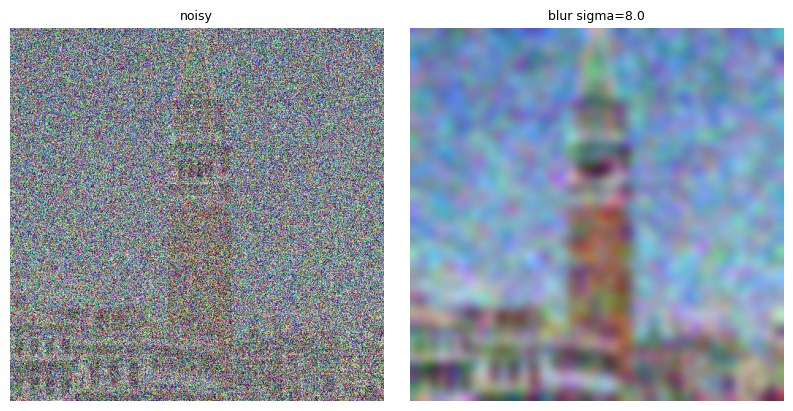

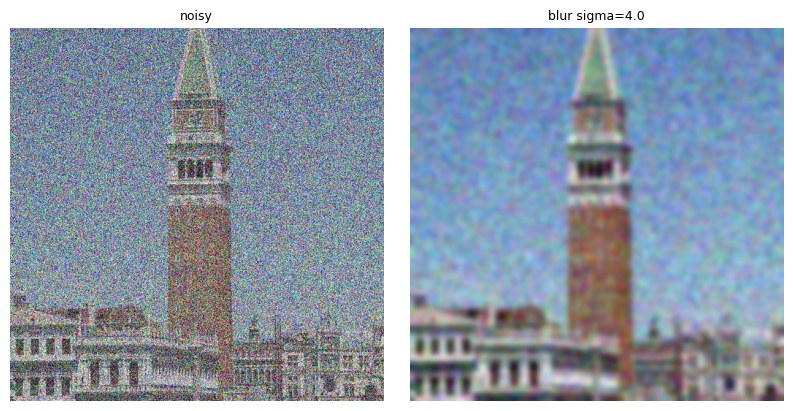

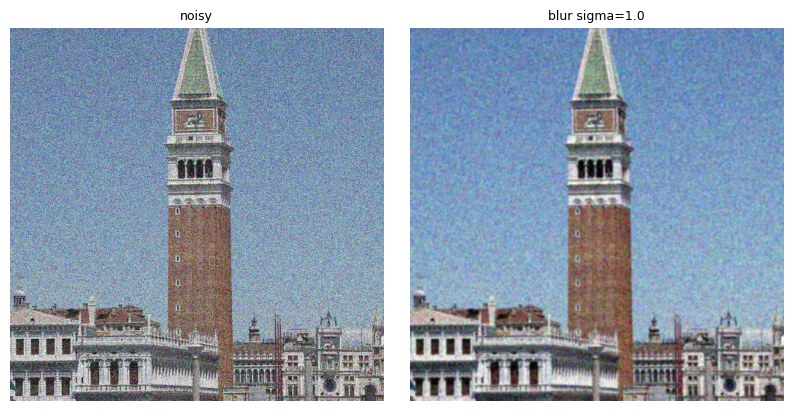

In [ ]:
# results

## 1.3 One-Step Denoising

Prompt: "a high quality photo". Rows are $t = 0.25, 0.50, 0.75$.

In [ ]:
def one_step_denoise(x, t, condition, predict_velocity):
    return x + (1-t)*predict_velocity(x, t, condition)

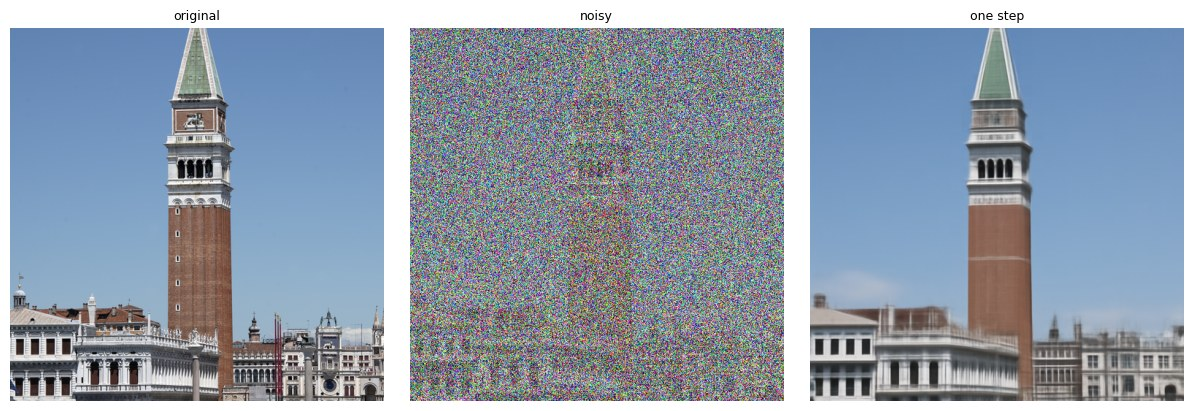

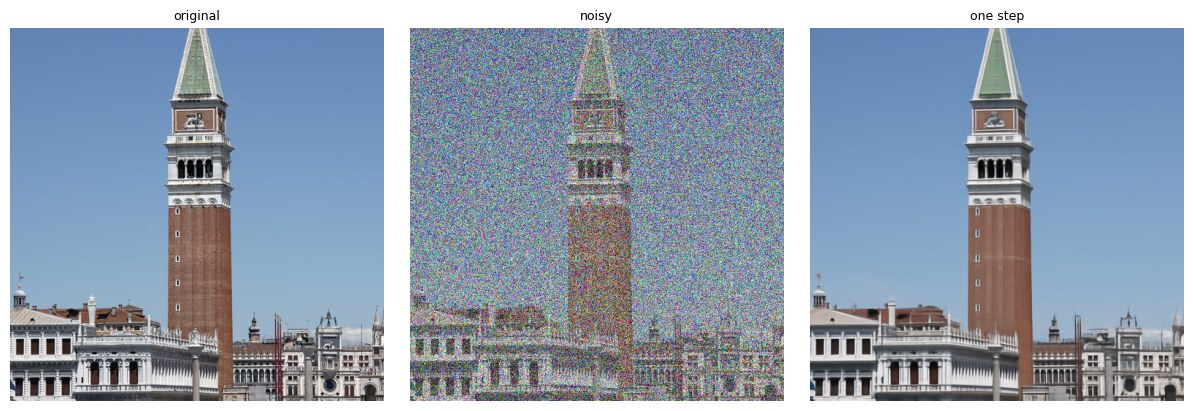

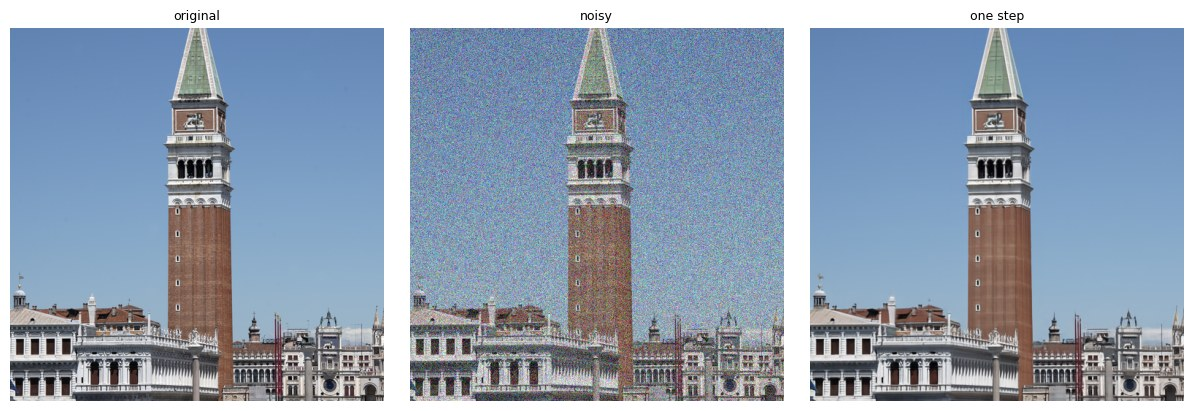

In [ ]:
# results

## 1.4 Visualizing Velocity

Updates share one symmetric RGB scale with zero at middle gray. The error maps (per-pixel RMS over RGB, computed before display scaling) share the same `vmin`/`vmax` at all three times.

In [ ]:
@torch.inference_mode()
def velocity_diagnostics(x_t, t, clean_image, epsilon, condition, predict_velocity):

    v_hat = predict_velocity(x_t, t, condition)
    predicted_update = (1-t) * v_hat

    v_gt = clean_image - epsilon
    target_update = (1-t) * v_gt

    diff = predicted_update - target_update
    error_map = (diff ** 2).mean(dim=1).sqrt()
    return predicted_update, target_update, error_map

Original image

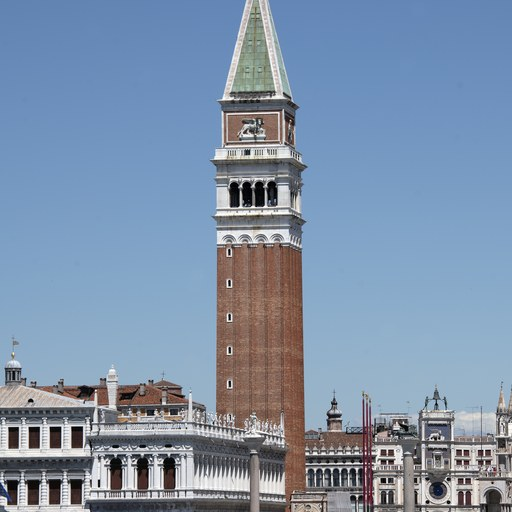

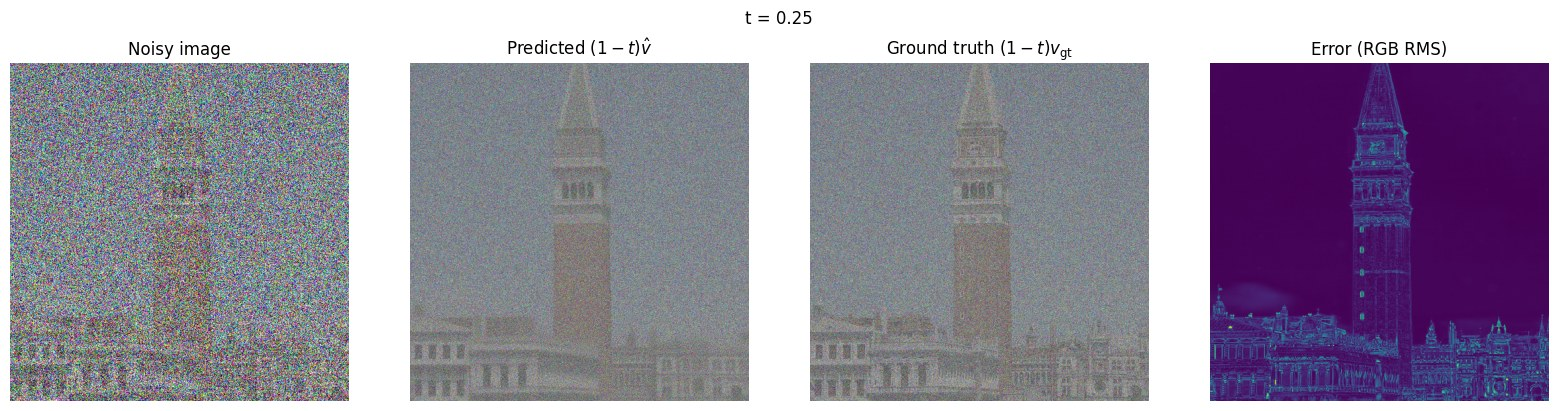

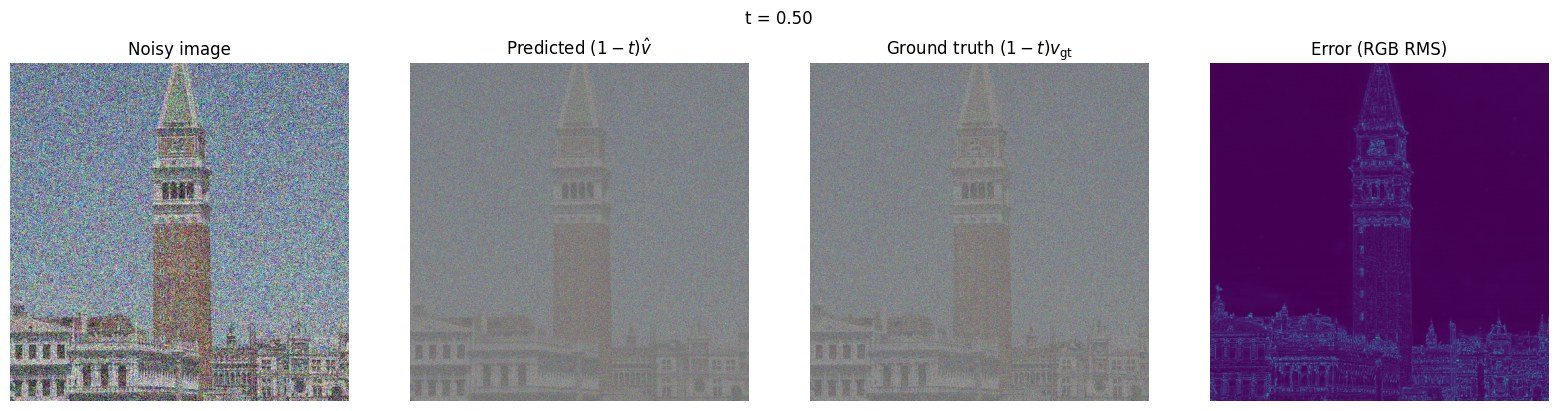

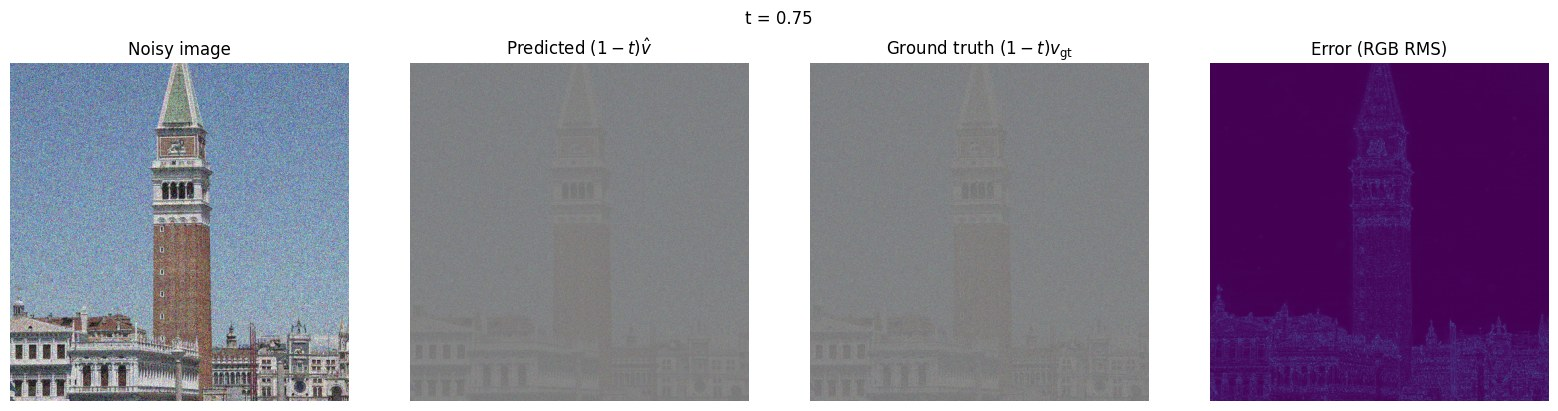

In [ ]:
# results

## 1.5 Iterative Denoising with Euler Sampling

Starting from the $t=0.50$ input with $h=0.02$ (25 updates). The first figure shows the initial state, every fifth update, and the final image; the second compares Gaussian blur, one-step denoising, and Euler sampling on the same input.

In [ ]:
@torch.inference_mode()
def euler_sample(x_start, t_start, step_size, velocity):
    x = x_start
    t = float(t_start)
    states = [(t, x)]
    step = 0
    while t < 1.0 - 1e-8:
        h = min(step_size, 1.0 - t)
        x = x + h * velocity(x, t)
        t = t + h
        step += 1
        if step % 5 == 0:
            states.append((t, x))
    if states[-1][0] < 1.0 - 1e-8:
        states.append((t, x))
    states[-1] = (1.0, states[-1][1])
    return x, states

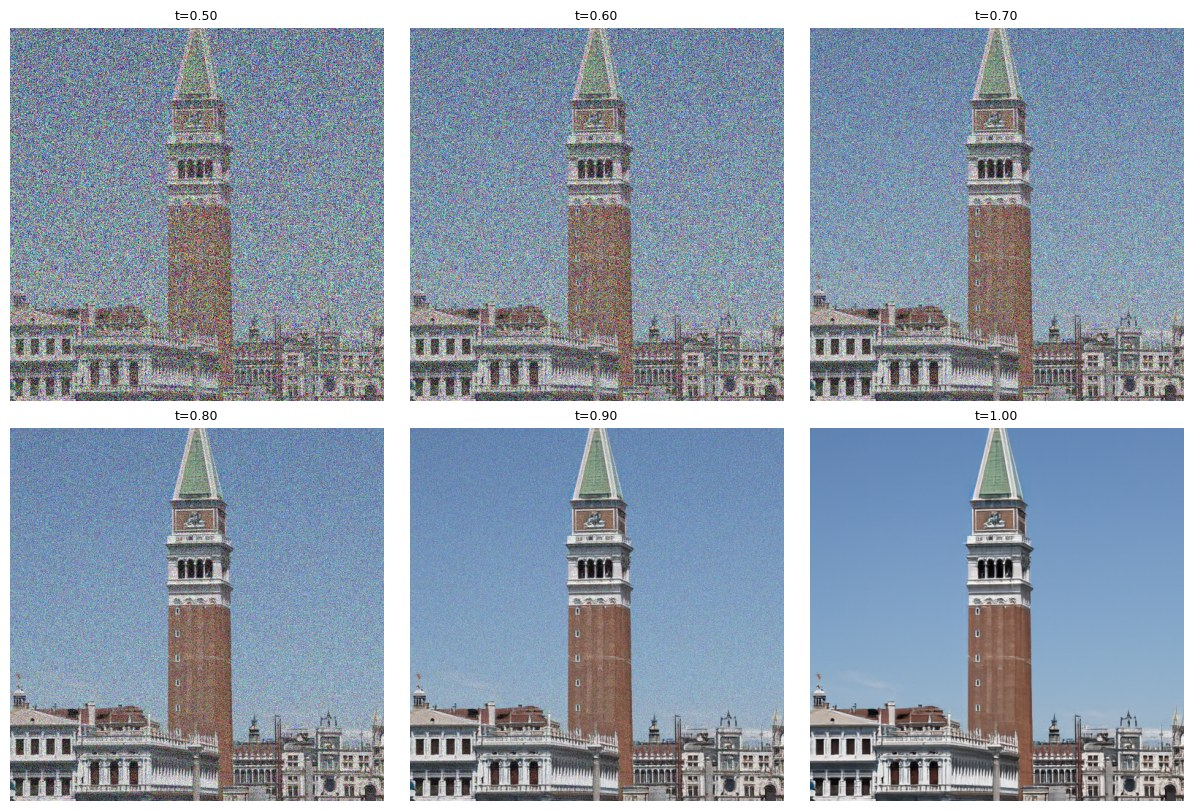

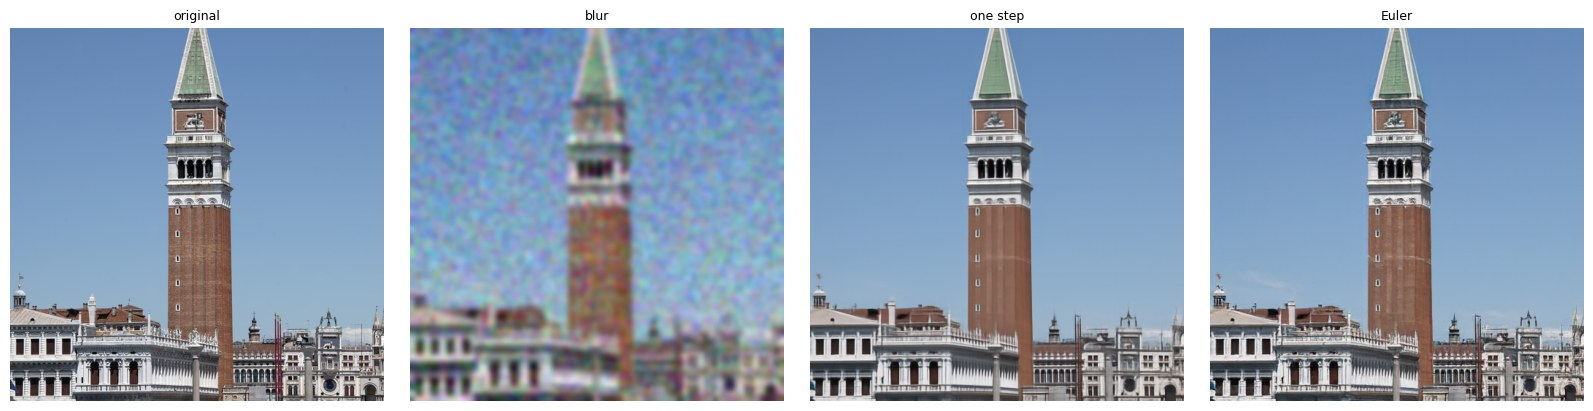

In [ ]:
# results

### Comparison

Gaussian blur (1.2) does a terrible job — as a pure low-pass filter it just smears the noise around rather than actually remove it. One-step denoising does a fairly good job, but because it jumps straight to the estimate in a single velocity prediction, any error goes uncorrected and the high frequency detail remains rather blurry. Euler sampling does the best job: by taking many small steps and re-evaluating the velocity at each one, it progressively refines detail a single jump misses. Comparing its result against one-step denoising, the vertical streaks on the tower are more prominent (and closer in resemblance to the original image) and the statue at the top of the tower is more defined.

## 1.6 Generating Images from Noise

Prompt: "a high quality photo", 50 Euler steps from pure noise, seeds 180–184.

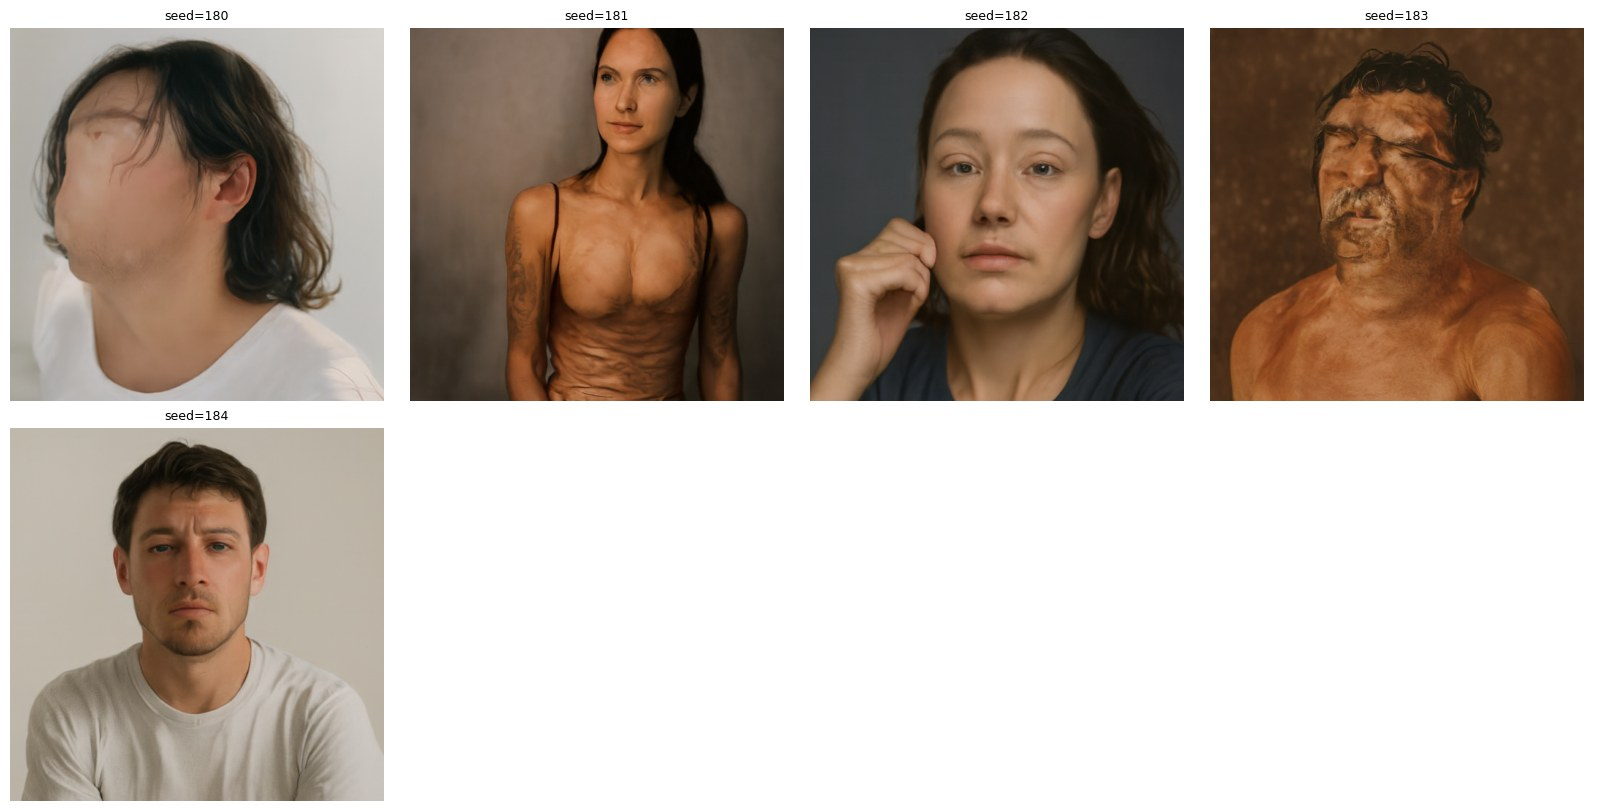

In [ ]:
# results

All 5 images are pictures of people/faces, likely because the model is mostly trained on pictures of people and faces. A prompt as generic as "a high quality photo" thus steers the model towards what it knows best. Because these are unguided samples, quality is hit-or-miss.

# 2. Conditional Generation and Guidance

## 2.1 Classifier-Free Guidance

$v_{cfg} = v_c + w(v_c - v_u)$ with $w=7$, $h=0.02$, and the empty-string prompt for $v_u$. Same seeds (180–184) as Section 1.6. With $w=0$ this reproduces the conditional prediction (checked by assertion).

In [ ]:
def cfg_velocity(x, t, condition, w, predict_velocity, null_condition=''):
    v_c = predict_velocity(x, t, condition)
    v_u = predict_velocity(x, t, null_condition)
    return v_c + w * (v_c - v_u)

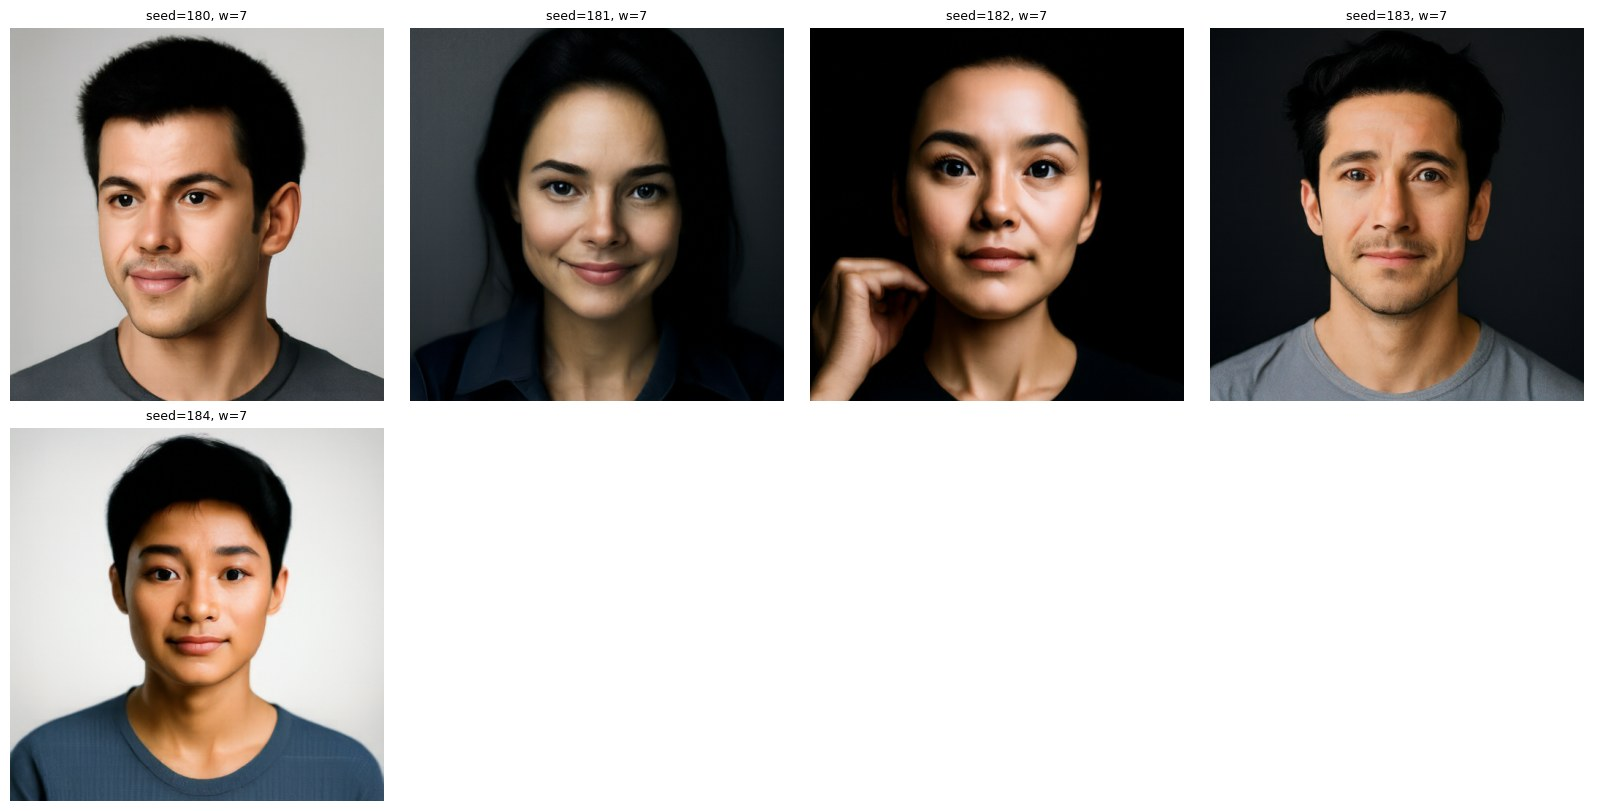

In [ ]:
# results

The images here are much more realistic than in the previous section. Strong prompt guidance pushes each image harder toward what a "high quality photo" looks like. But the tradeoff is diversity: the photos are similarly centered portraits.

# 3. Creative Applications

Throughout: $h=0.02$, $w=7$, empty-string unconditional prompt.

## 3.1 Image-to-Image Editing

Prompt: "a high quality photo", starting times 0.02, 0.04, 0.06, 0.10, 0.14, 0.25, 0.50. Inputs: the Campanile and two of my own test images.

In [ ]:
def edit(image, noise, t_start, condition, predict_velocity, w=7, step_size=0.02):
    x_start = interpolate(image, noise, t_start)
    velocity = lambda x, t: cfg_velocity(x, t, condition, w, predict_velocity)
    final, _ = euler_sample(x_start, t_start, step_size, velocity)
    return final

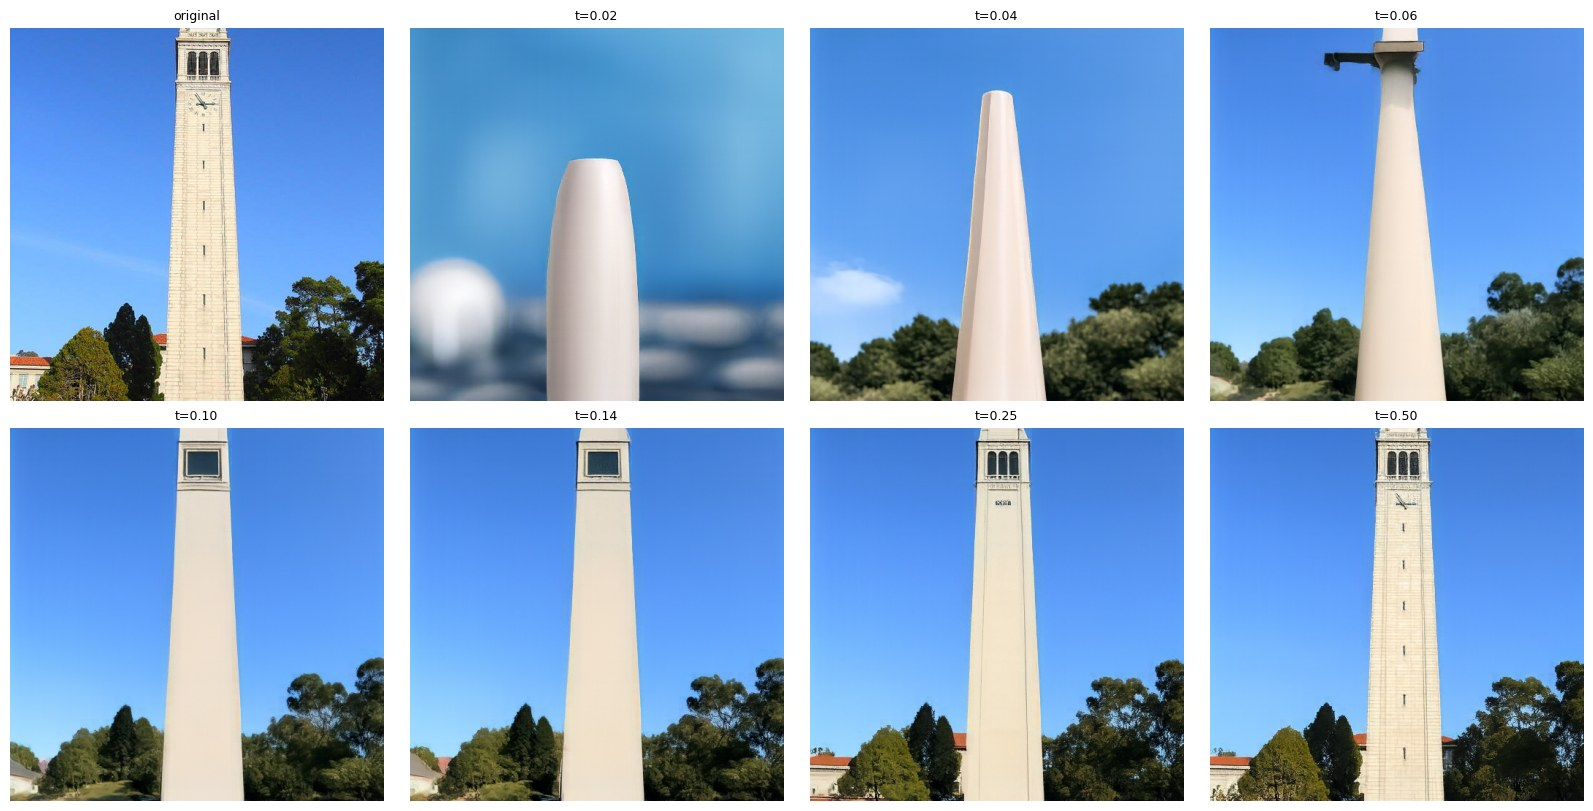

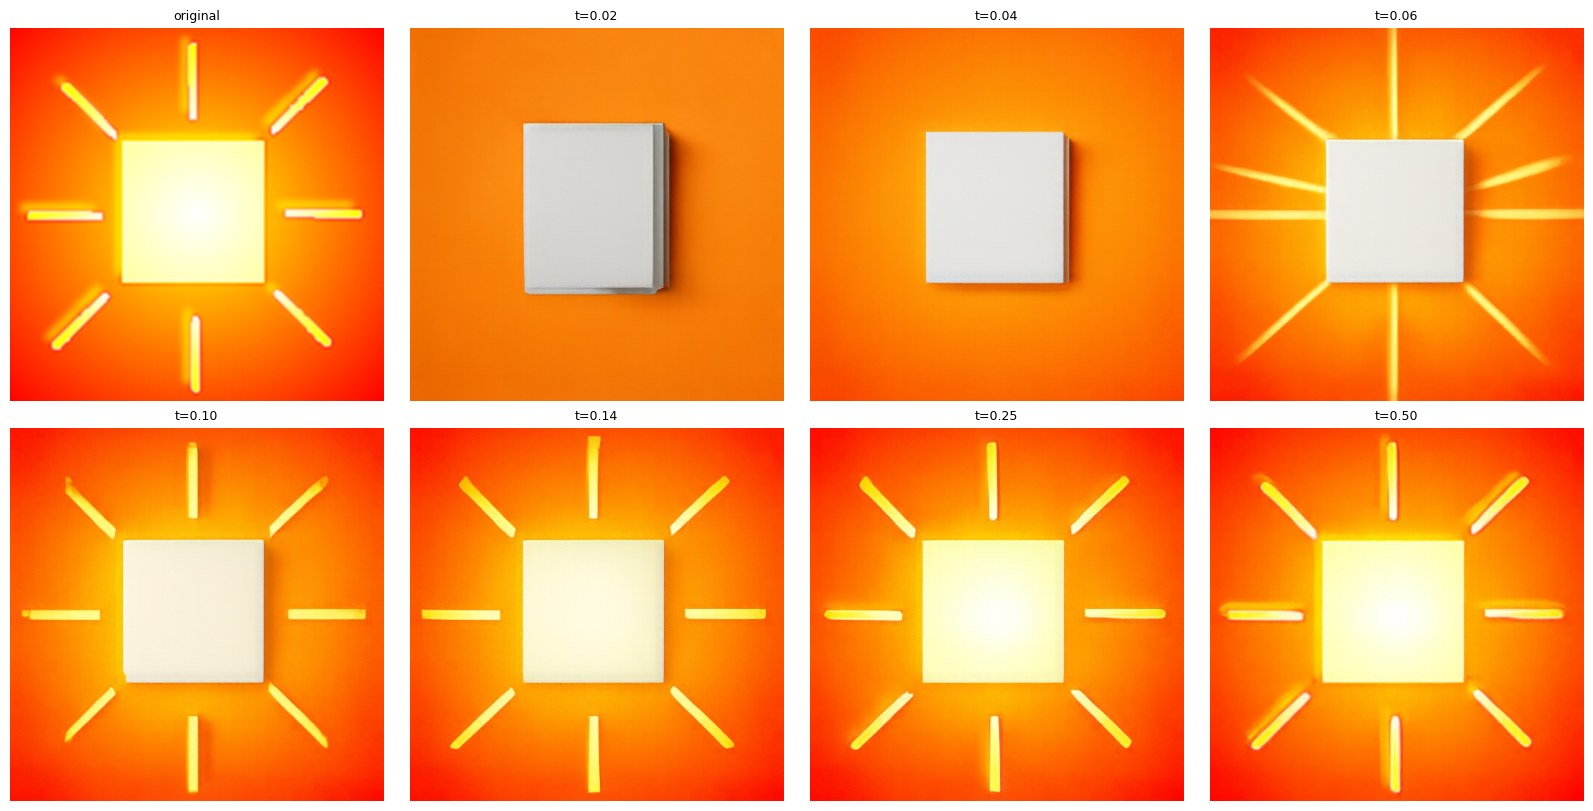

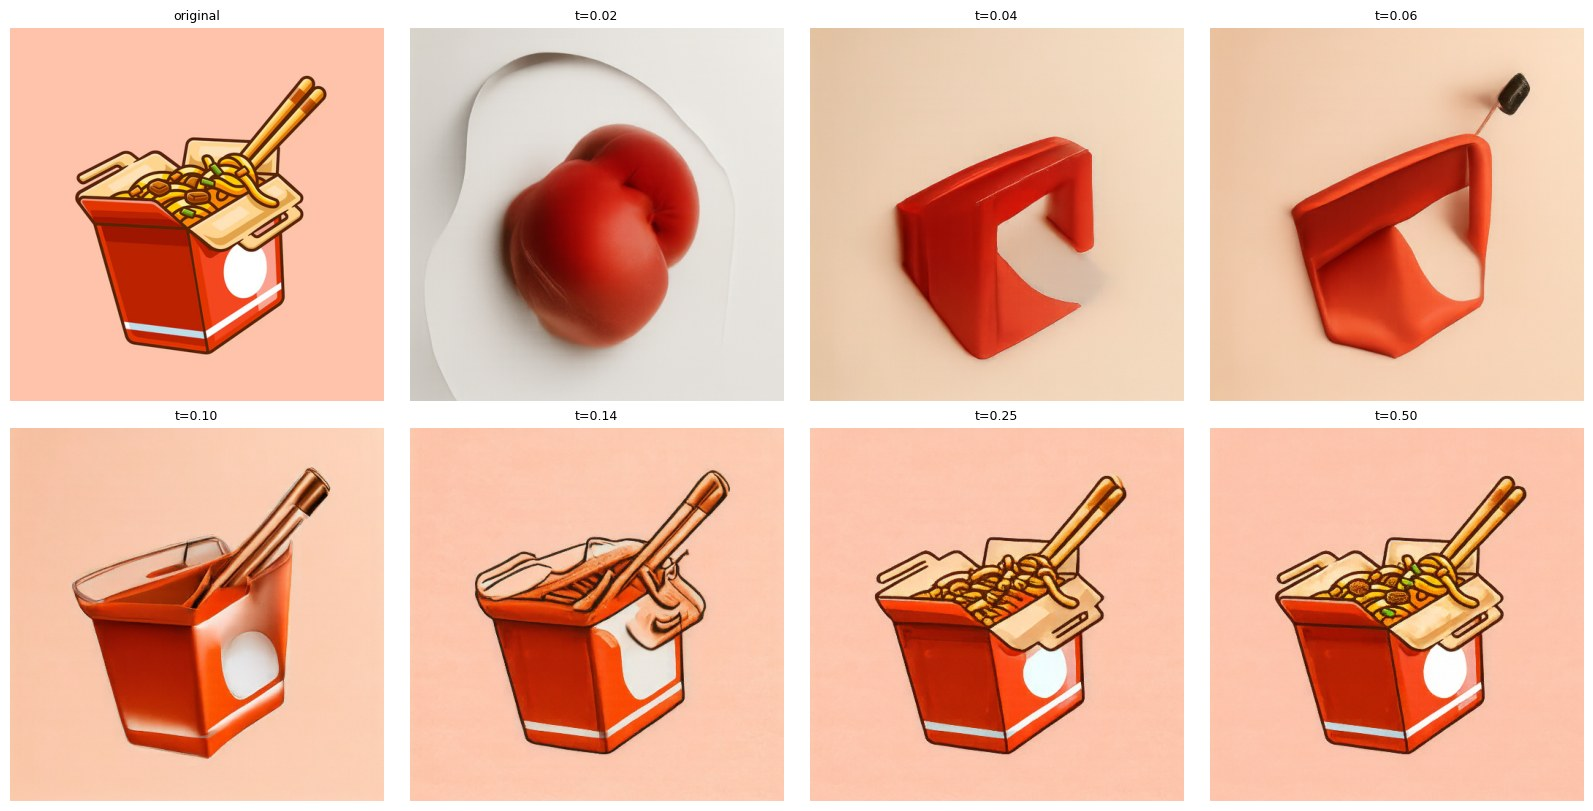

In [ ]:
# results

### Web image and hand-drawn images

One image from the web, then two of my own drawings.

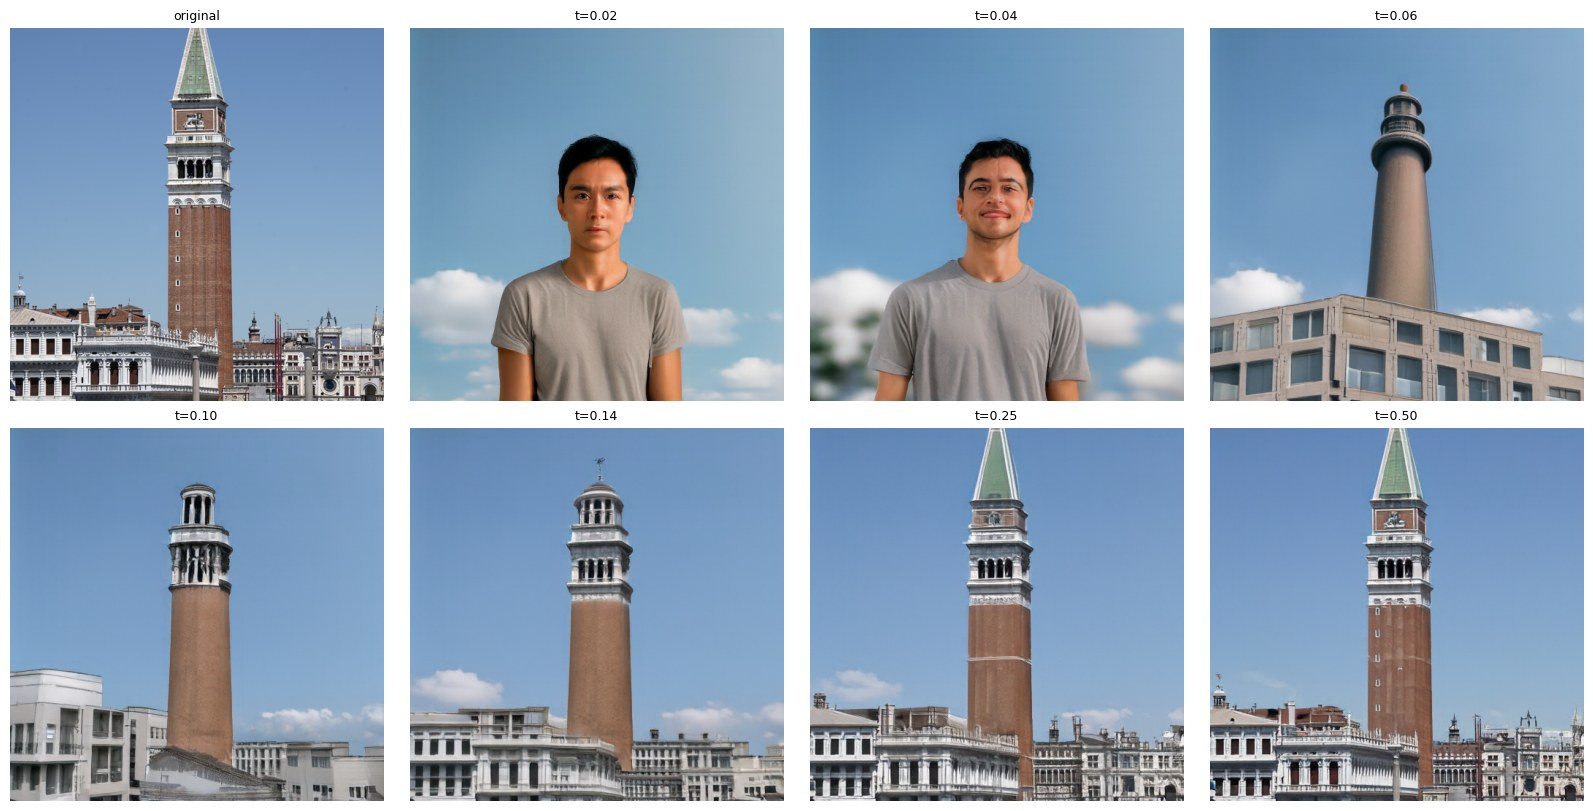

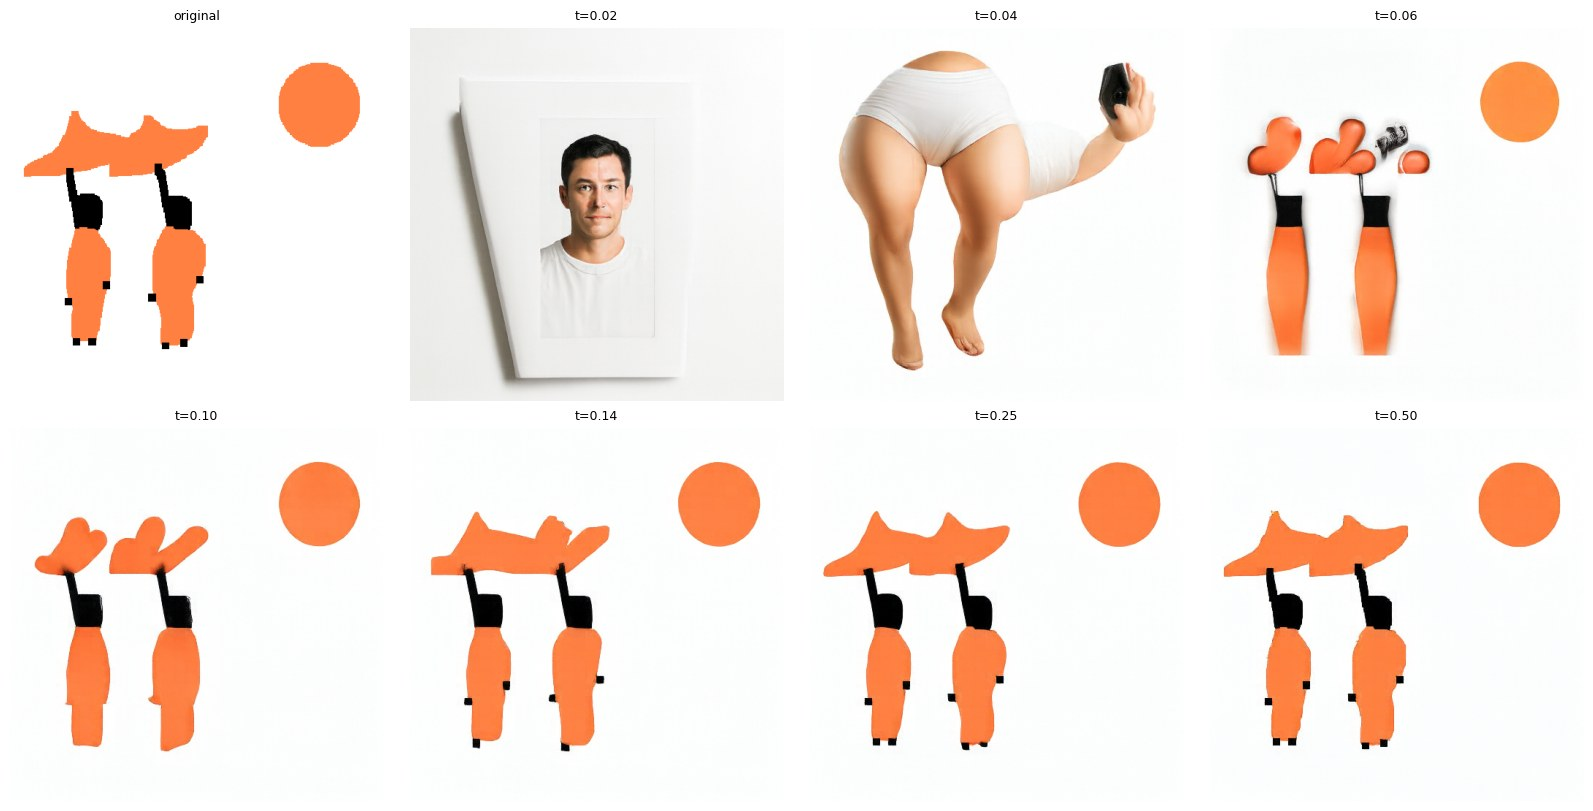

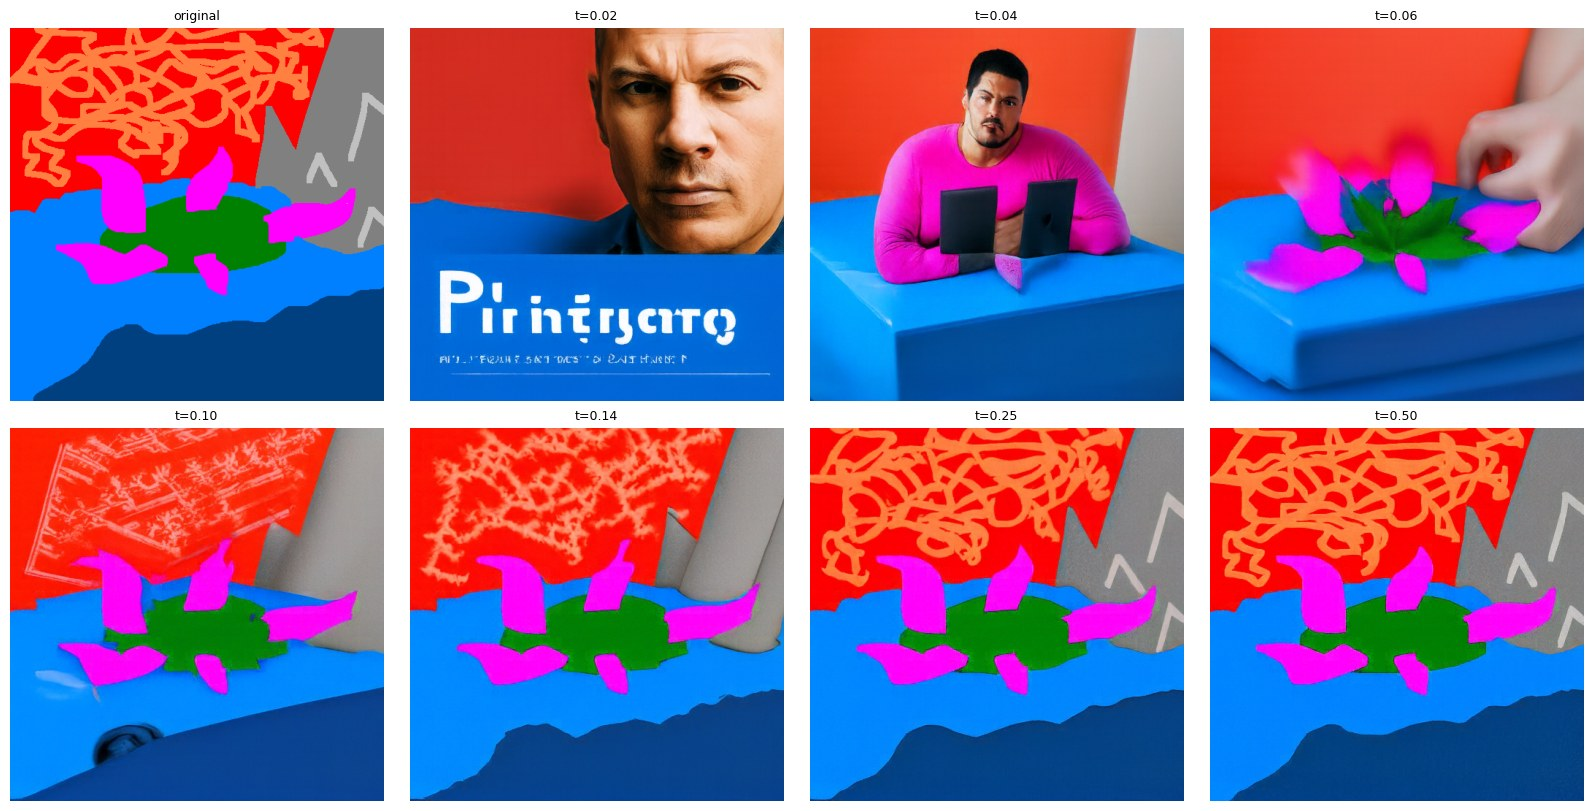

In [ ]:
# results

At t=0.02, the image is mostly noise, so the sampler generates a photo that matches the general color layout of the original image but not much else. By t=0.10, the sampler generates something that looks a lot like the campanile. 

A similar pattern is seen for the other starter images. At t=0.02 and t=0.04, the result diverges quite strongly from the original. t=0.06 is the transition zone, and by t=0.10, the original image is mostly recovered.

## 3.2 Text-Guided Image Editing

Same seven starting times; each prompt is shown above its row.

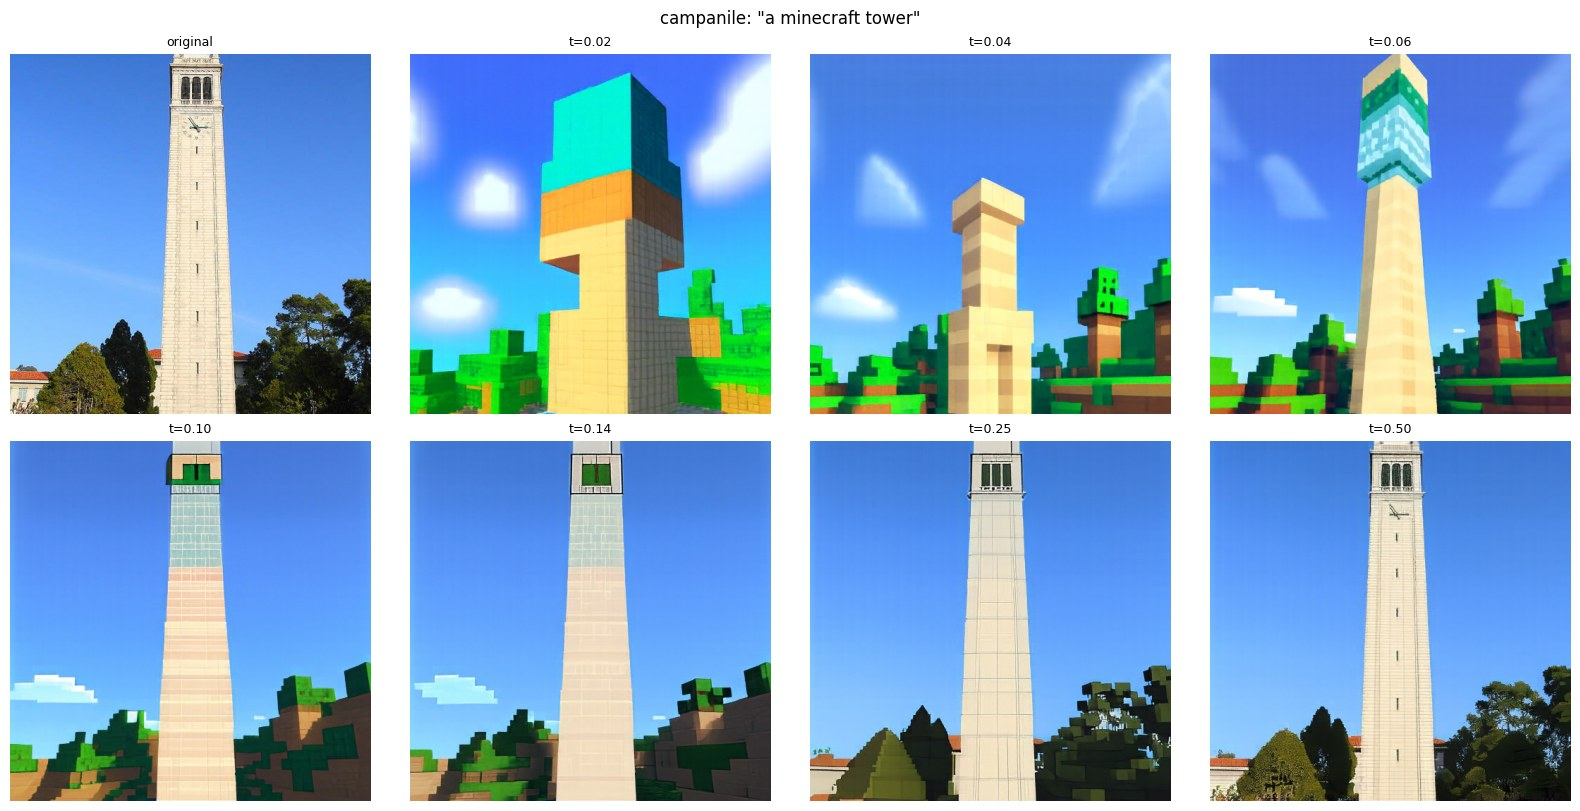

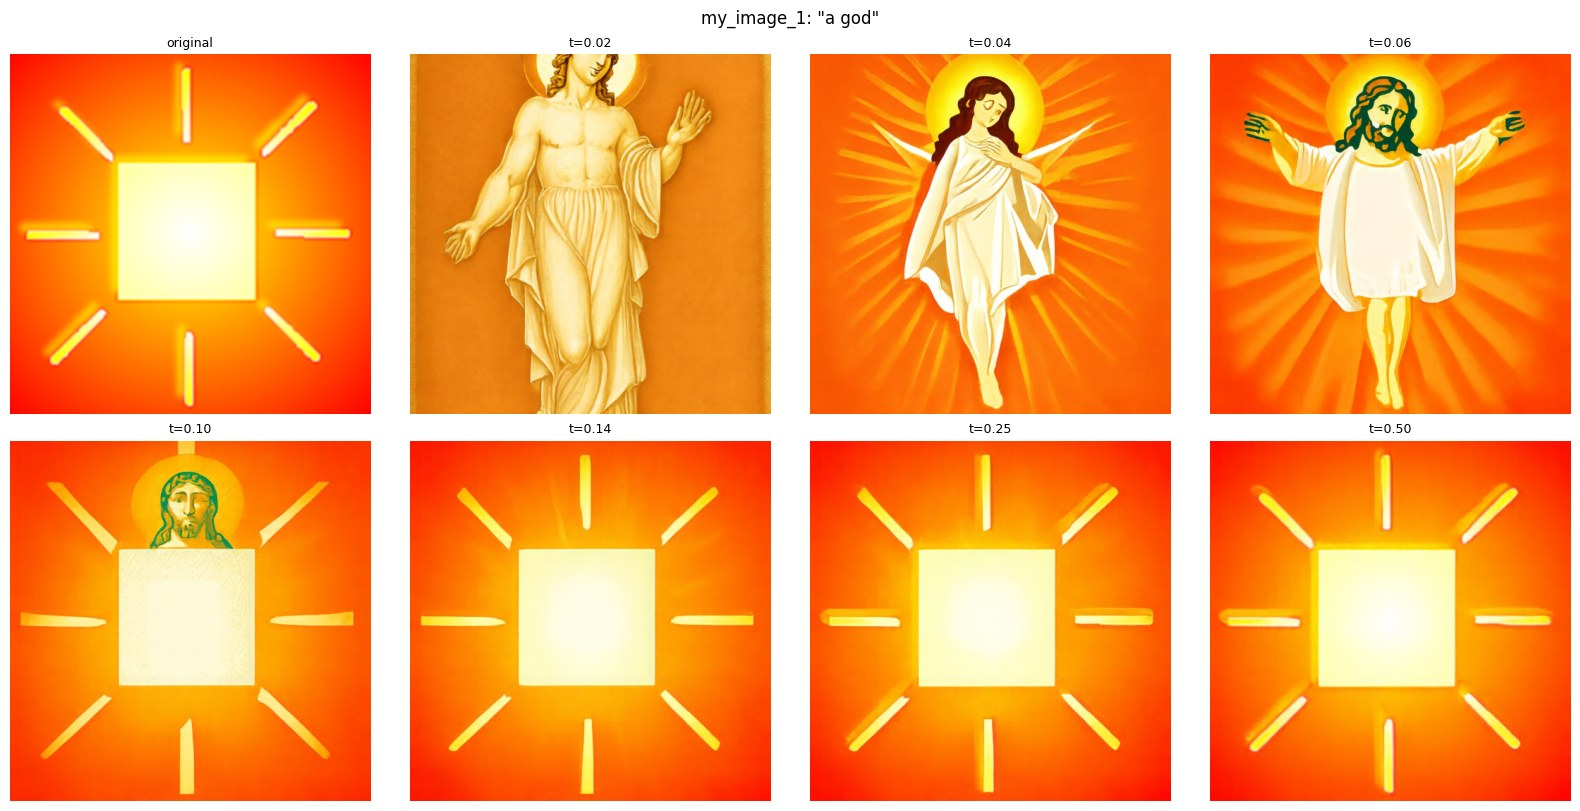

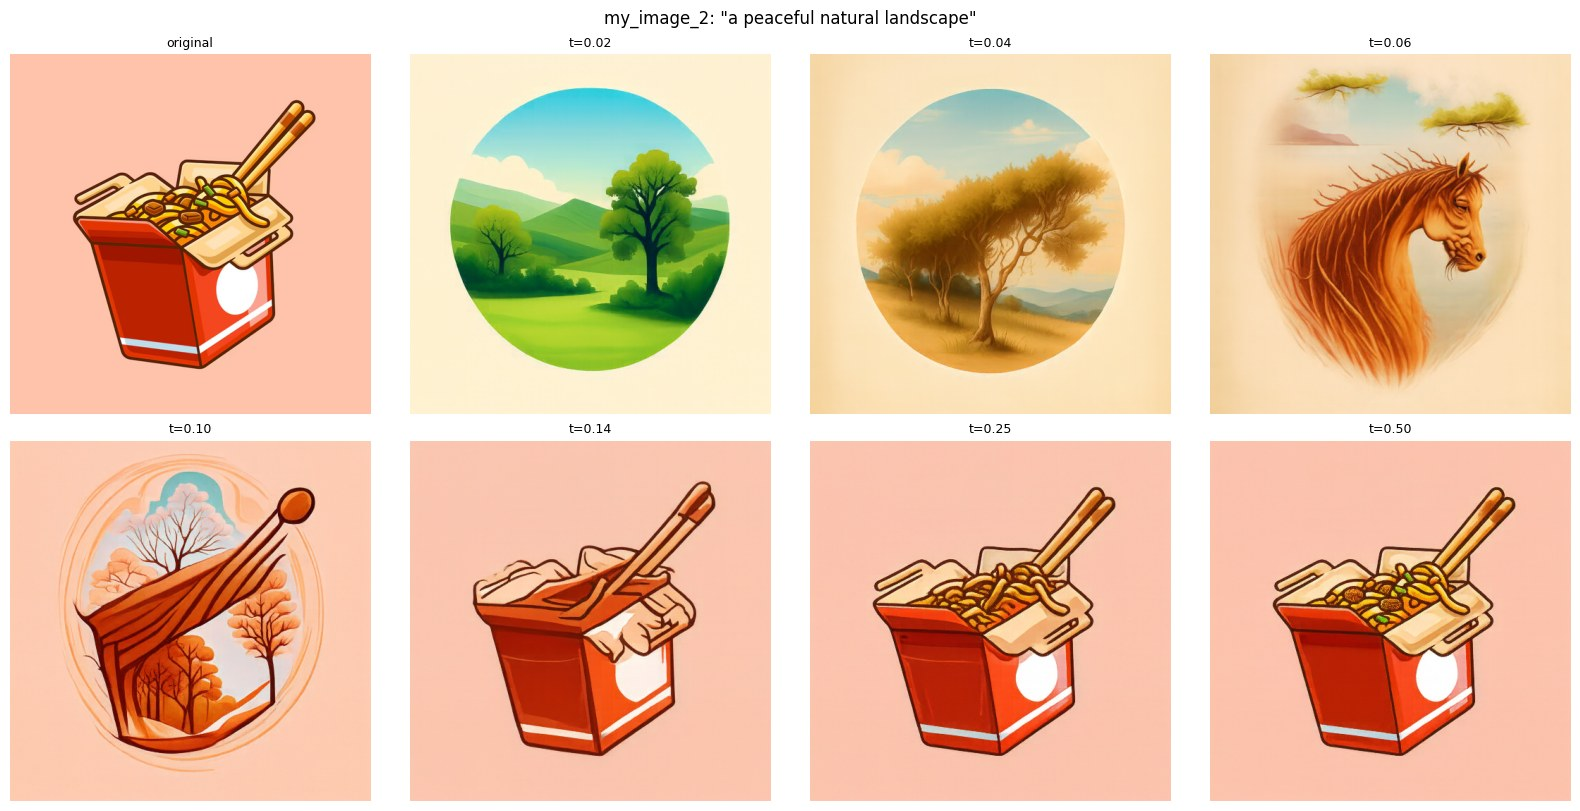

In [ ]:
# results

With a text prompt, the starting time controls how much the prompt can override the original. At t=0.02–0.06 the start is almost pure noise, so the prompt dominates: the Campanile becomes a blocky Minecraft tower, the sun becomes a radiant god figure, and the noodle box becomes a landscape vignette (and, at t=0.06, a horse). 

 Around t=0.10 the two blend: the Campanile keeps its shape but gains a pixelated top and blocky Minecraft trees, a haloed face appears above the sun's square, and trees appear inside the noodle box. 
 
 From t=0.14 on, the original structure is locked in and the prompt only nudges small details (e.g. the blocky trees at the Campanile's base at t=0.14), and by t=0.50 the edits are nearly identical to the originals.

## 3.3 Visual Anagrams

The velocity is the average of $v_{cfg}(x_t, t, c_a)$ and $F(v_{cfg}(F(x_t), t, c_b))$, where $F$ rotates by 180°. Each illusion is shown upright (left) and rotated (right).

In [ ]:
def visual_anagrams(noise, condition_a, condition_b, predict_velocity, w=7, step_size=0.02):
    def velocity(x, t):
        v_a = cfg_velocity(x, t, condition_a, w, predict_velocity)
        v_b = rotate180(cfg_velocity(rotate180(x), t, condition_b, w, predict_velocity))
        return (v_a + v_b) / 2
    final, _ = euler_sample(noise, 0, step_size, velocity)
    return final

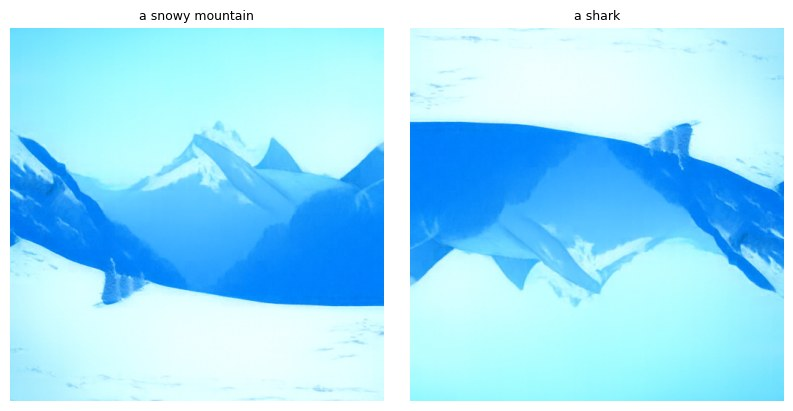

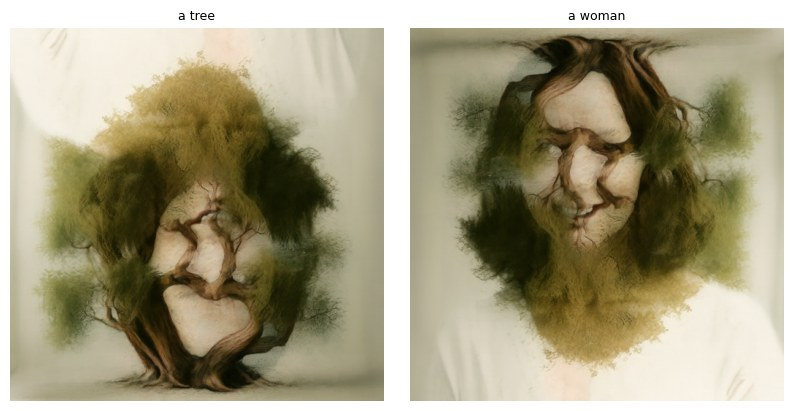

In [ ]:
# results

## 3.4 Hybrid Images

The velocity is the low-pass of the distant prompt's CFG velocity plus the high-pass of the close prompt's, using a Gaussian blur with kernel size 265 and sigma 16. Each hybrid is shown at full size (close view) and downsampled to 64×64 (distant view).

In [ ]:
def make_hybrids(noise, condition_a, condition_b, predict_velocity, w=7, step_size=0.02):
    def velocity(x, t):
        v_a = cfg_velocity(x, t, condition_a, w, predict_velocity)   # distant / low-freq prompt
        v_b = cfg_velocity(x, t, condition_b, w, predict_velocity)   # close / high-freq prompt
        return lowpass(v_a) + (v_b - lowpass(v_b))
    final, _ = euler_sample(noise, 0, step_size, velocity)
    return final

Close: an ink drawing of an eagle

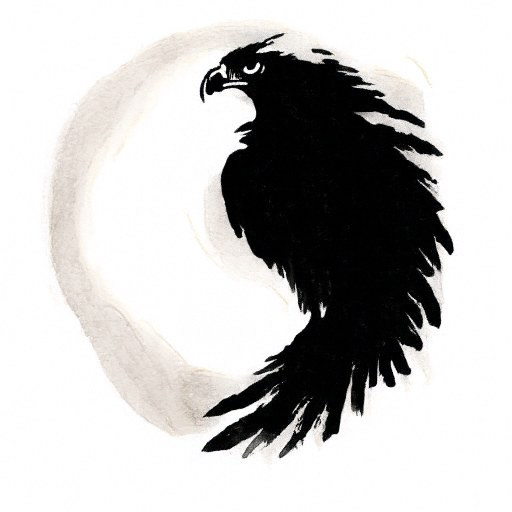

Distant: an ink drawing of yin yang

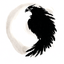

Close: a watercolor of a fruit stand

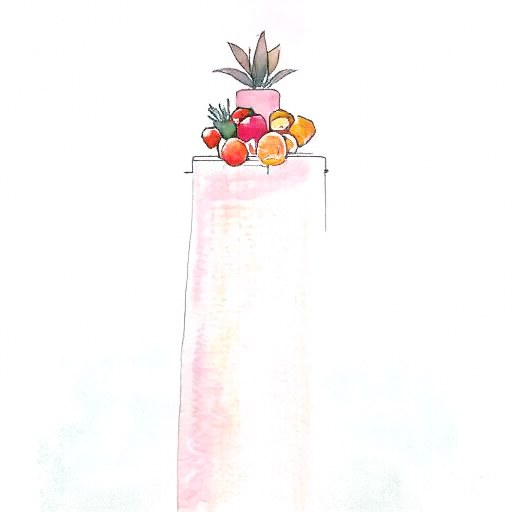

Distant: a watercolor of a lighthouse

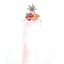

In [ ]:
# results

# Part B: Flow Matching from Scratch

# Part 1: Training a Single-Step Denoising UNet

## 1.1 Implementing the UNet

In [ ]:
class Conv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.net = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=1, padding=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

class DownConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.net = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=2, padding=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

class UpConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.net = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=4, stride=2, padding=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

class Flatten(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.AvgPool2d(kernel_size=7)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

class Unflatten(nn.Module):
    def __init__(self, in_channels: int):
        super().__init__()
        self.net = nn.ConvTranspose2d(in_channels, in_channels, kernel_size=7, stride=7)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

class ConvBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.net = nn.Sequential(
            Conv(in_channels, out_channels),
            nn.BatchNorm2d(out_channels),
            nn.GELU()
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

class DownBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.net = nn.Sequential(
            DownConv(in_channels, out_channels),
            nn.BatchNorm2d(out_channels),
            nn.GELU()
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

class UpBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.net = nn.Sequential(
            UpConv(in_channels, out_channels),
            nn.BatchNorm2d(out_channels),
            nn.GELU()
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

In [ ]:
class UnconditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_hiddens: int,
    ):
        super().__init__()
        D = num_hiddens
        self.conv_in = ConvBlock(in_channels, D)
        self.down1 = DownBlock(D, D)
        self.down2 = DownBlock(D, 2*D)
        self.flatten = Flatten()
        self.flat = ConvBlock(2*D, 2*D)
        self.unflatten = Unflatten(2*D)
        self.unflat = ConvBlock(2*D, 2*D)
        self.up1 = UpBlock(2*D + 2*D, D)
        self.up2 = UpBlock(D + D, D)
        self.out = ConvBlock(D + D, D)
        self.final = Conv(D, in_channels)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        x1 = self.conv_in(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        z = self.flat(self.flatten(x3))
        y = self.unflat(self.unflatten(z))
        y = self.up1(torch.cat([y, x3], dim=1))
        y = self.up2(torch.cat([y, x2], dim=1))
        y = self.out(torch.cat([y, x1], dim=1))
        return self.final(y)

## 1.2 Using the UNet to Train a Denoiser

Noising process $z = x + \sigma\epsilon$ for $\sigma = 0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0$:

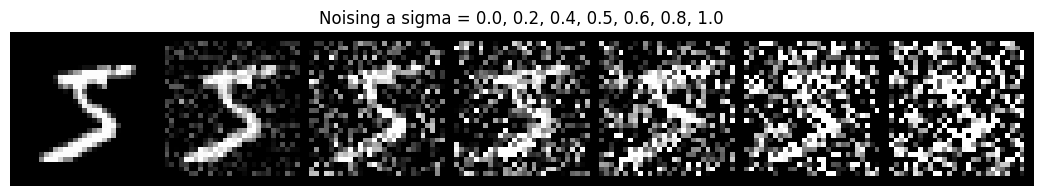

In [ ]:
# results

### 1.2.1 Training

Trained on $\sigma=0.5$ with batch size 256, 5 epochs, $D=128$, Adam with learning rate 1e-4; fresh noise every batch. Test-set results after the 1st and 5th epochs, then the training loss curve:

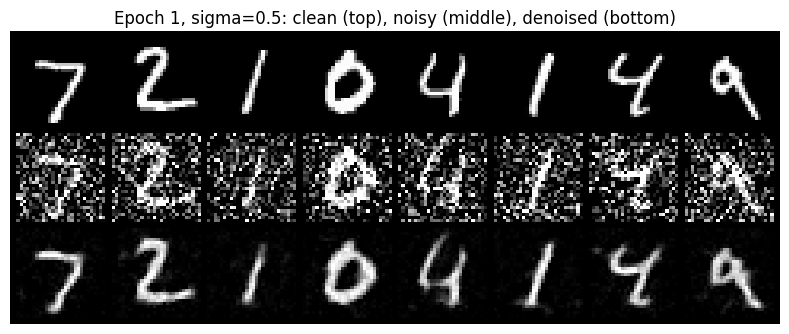

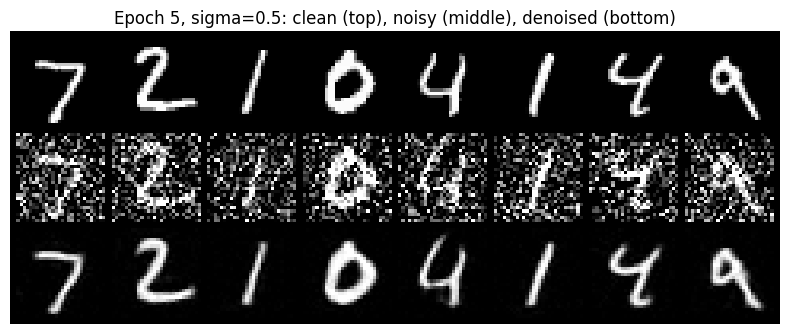

In [ ]:
# results

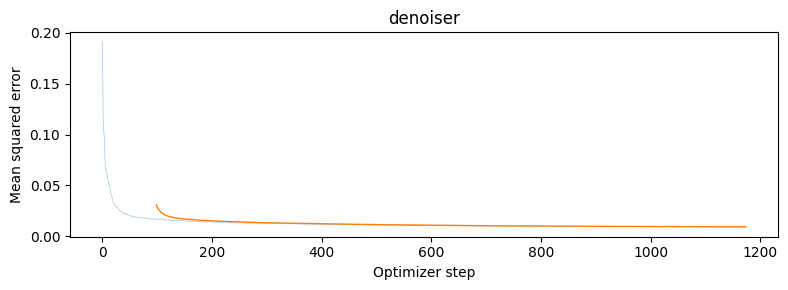

In [ ]:
# results

### 1.2.2 Out-of-Distribution Testing

The denoiser trained on $\sigma=0.5$, applied to the same test digits at $\sigma = 0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0$ (odd rows: noisy input; even rows: denoised output).

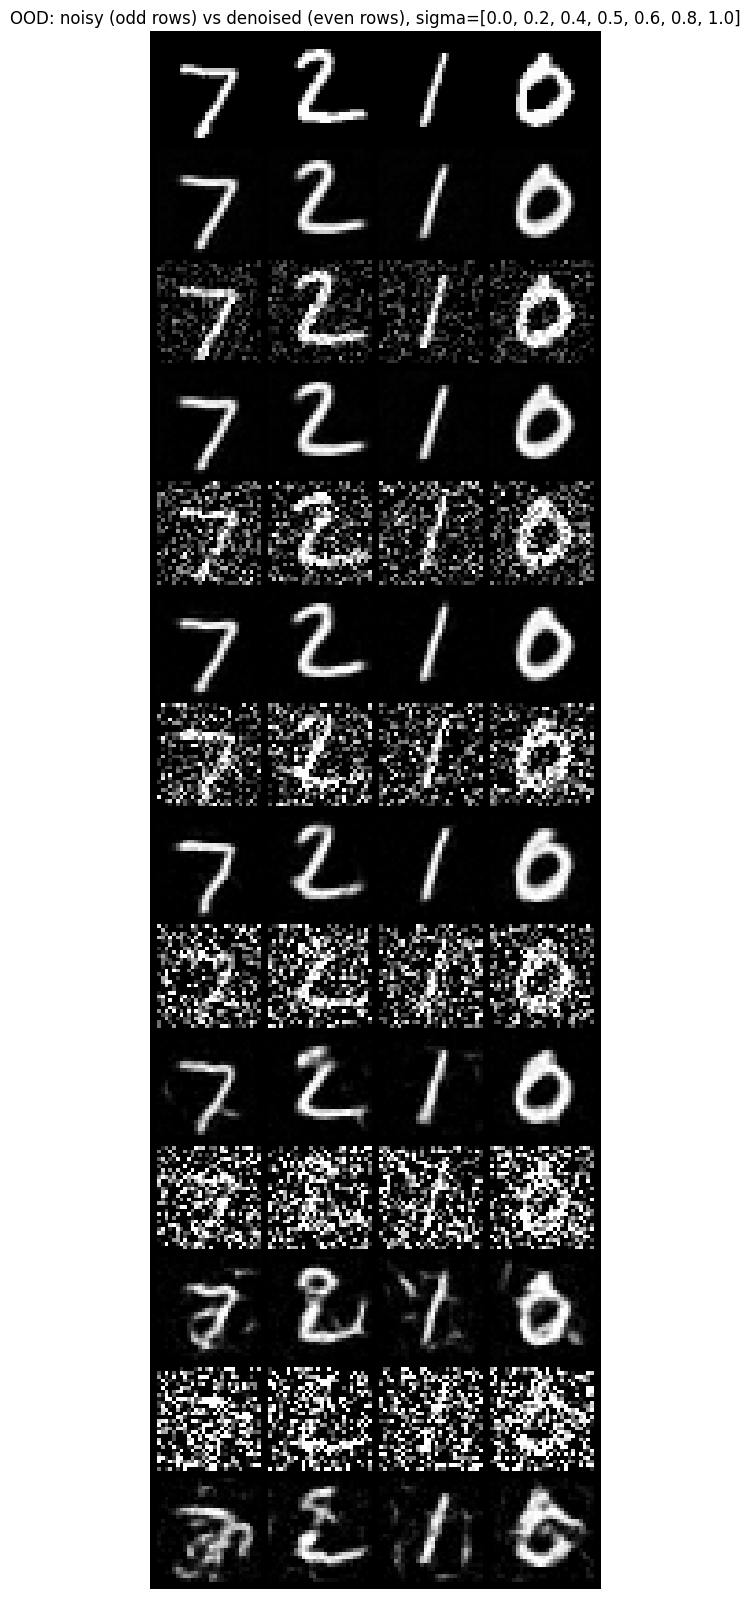

In [ ]:
# results

### 1.2.3 Denoising Pure Noise

Same setup, but the input is pure Gaussian noise. Training loss, then samples after the 1st and 5th epochs:

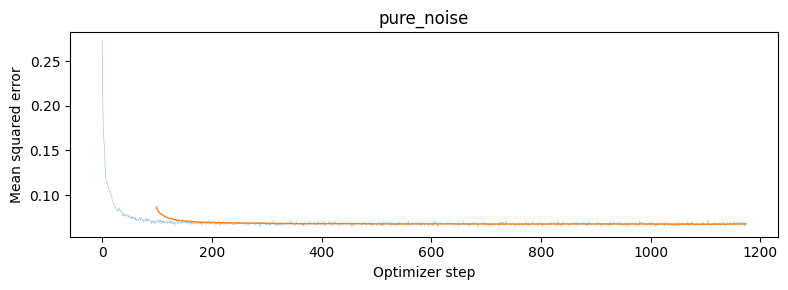

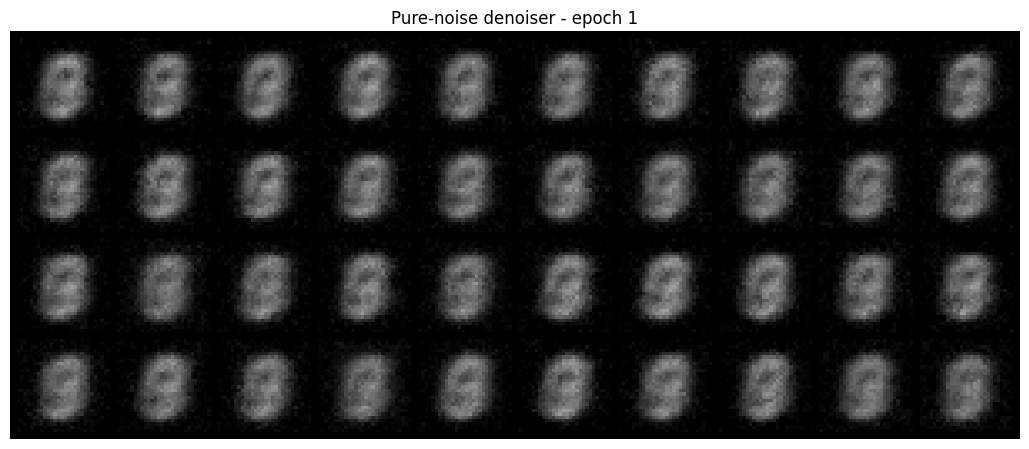

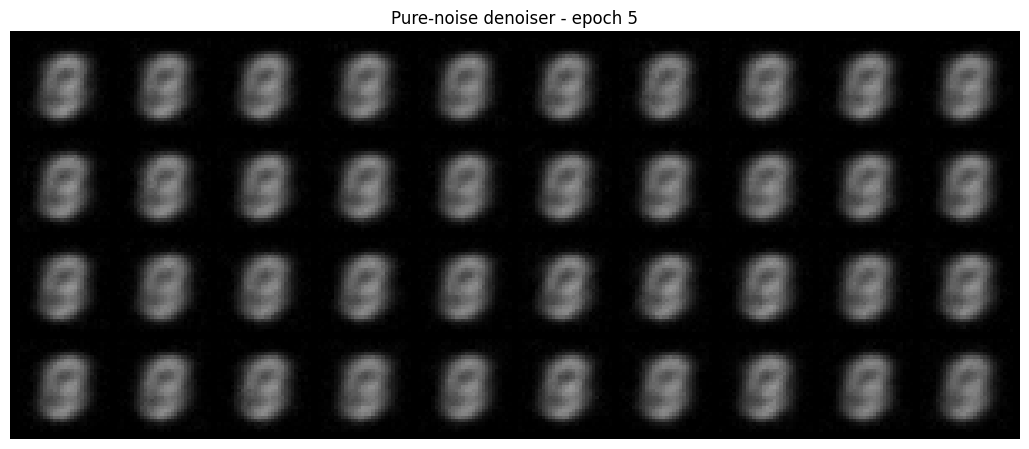

In [ ]:
# results

When the input is pure noise, the best the network can do is predict the same output for every input. Under an MSE loss, the optimal constant prediction is the mean of the training targets, so the network learns the average of all MNIST digits. That's what we see: every output is the same blurry superposition of all ten digits.

# Part 2: Training a Flow Matching Model

## 2.1 Adding Time Conditioning to the UNet

The normalized time $t$ is embedded with two FCBlocks, which are added after the unflatten block and after the first up block.

In [ ]:
class FCBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_channels, out_channels), nn.GELU(),
            nn.Linear(out_channels, out_channels)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

class TimeConditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_classes: int,
        num_hiddens: int,
    ):
        super().__init__()
        D = num_hiddens
        self.conv_in = ConvBlock(in_channels, D)
        self.down1, self.down2 = DownBlock(D, D), DownBlock(D, 2*D)
        self.flatten, self.flat = Flatten(), ConvBlock(2*D, 2*D)
        self.unflatten, self.unflat = Unflatten(2*D), ConvBlock(2*D, 2*D)
        self.up1 = UpBlock(4*D, D)
        self.up2 = UpBlock(2*D, D)
        self.out = ConvBlock(2*D, D)
        self.final = Conv(D, in_channels)
        self.t1, self.t2 = FCBlock(1, 2*D), FCBlock(1, D)

    def forward(
        self,
        x: torch.Tensor,
        t: torch.Tensor,
    ) -> torch.Tensor:
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        t = t.view(-1, 1).float()
        t1 = self.t1(t)[:, :, None, None]
        t2 = self.t2(t)[:, :, None, None]
        x1 = self.conv_in(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        y = self.unflat(self.unflatten(self.flat(self.flatten(x3))))
        y = y + t1
        y = self.up1(torch.cat([y, x3], 1))
        y = y + t2
        y = self.up2(torch.cat([y, x2], 1))
        y = self.out(torch.cat([y, x1], 1))
        return self.final(y)

Training (Algorithm 1) and sampling (Algorithm 2):

In [ ]:
def time_fm_forward(
    unet: TimeConditionalUNet,
    x_1: torch.Tensor,
    num_ts: int,
) -> torch.Tensor:
    unet.train()
    x_0 = torch.randn_like(x_1)                     
    t = torch.rand(x_1.shape[0], device=x_1.device) 
    tb = t[:, None, None, None]
    x_t = (1 - tb) * x_0 + tb * x_1                   
    v_target = x_1 - x_0                             
    v_pred = unet(x_t, t)
    return F.mse_loss(v_pred, v_target)

In [ ]:
@torch.inference_mode()
def time_fm_sample(
    unet: TimeConditionalUNet,
    img_wh: tuple[int, int],
    num_ts: int,
    seed: int = 0,
) -> torch.Tensor:
    unet.eval()
    n = 40                                            # how many to generate (match your grid)
    g = torch.Generator(device=device).manual_seed(seed)
    H, W = img_wh
    x = torch.randn(n, 1, H, W, device=device, generator=g)   # start at pure noise
    dt = 1.0 / num_ts
    for i in range(num_ts):
        t = torch.full((n,), i * dt, device=device)
        x = x + dt * unet(x, t)                        # Euler step
    return x

## 2.2 Training the Time-Conditioned UNet

Batch size 64, $D=64$, Adam with initial learning rate 1e-2, exponential decay $\gamma = 0.1^{1/10}$ stepped once per epoch, 10 epochs.

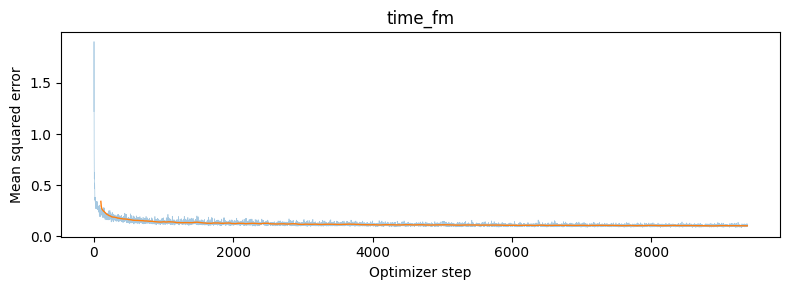

In [ ]:
# results

## 2.3 Sampling from the Time-Conditioned UNet

Samples (50 Euler steps, same seed) after epochs 1, 5, and 10.

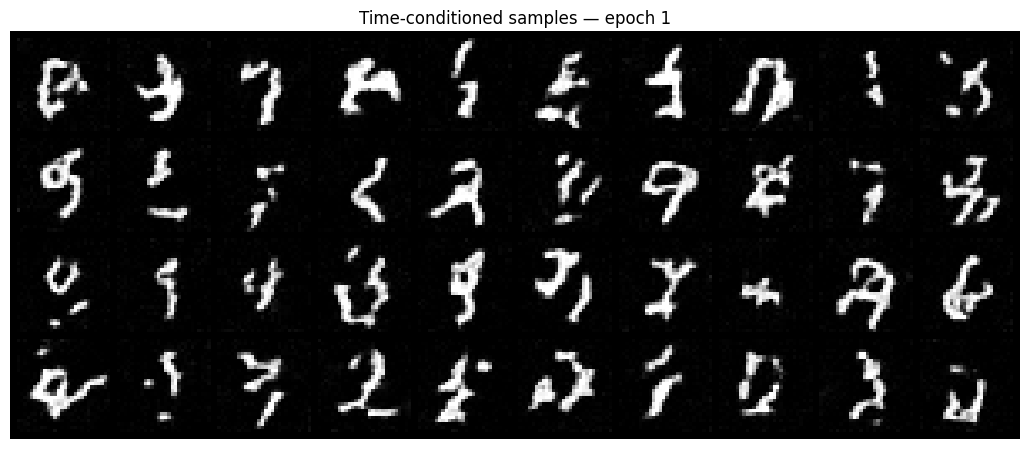

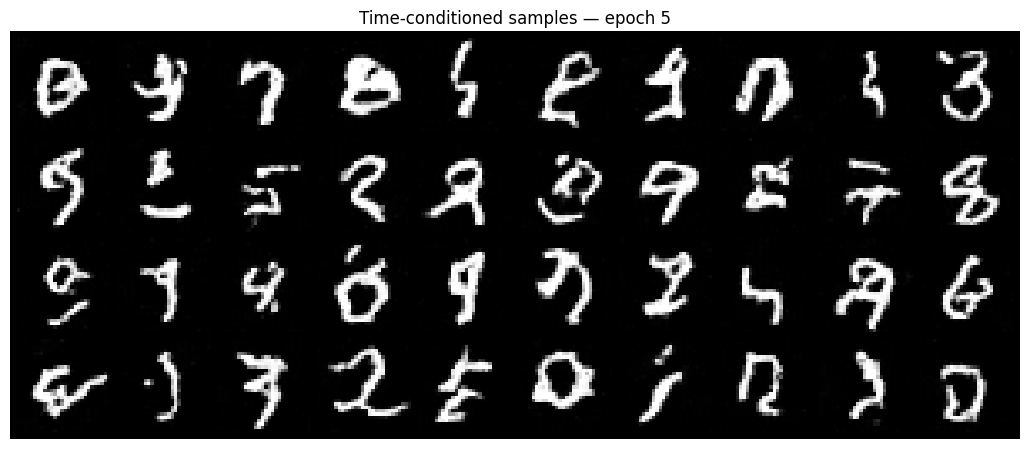

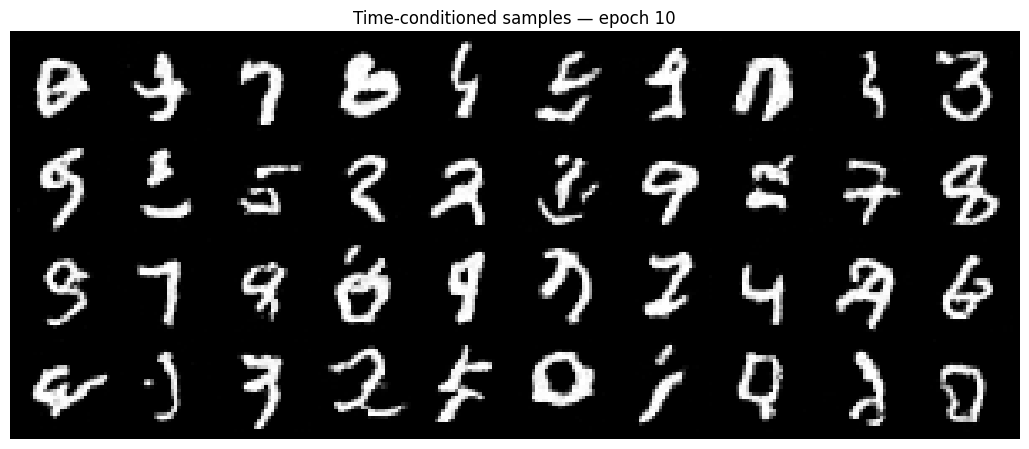

In [ ]:
# results

## 2.4 Adding Class-Conditioning to the UNet

The one-hot class vector $c$ goes through two more FCBlocks, which scale the features before the time embedding is added. $c$ is zeroed with probability $p_{uncond}=0.1$ during training so the same network also learns the unconditional velocity for classifier-free guidance.

In [ ]:
class ClassConditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_classes: int,
        num_hiddens: int,
    ):
        super().__init__()
        D = num_hiddens; self.num_classes = num_classes
        self.conv_in = ConvBlock(in_channels, D)
        self.down1, self.down2 = DownBlock(D, D), DownBlock(D, 2*D)
        self.flatten, self.flat = Flatten(), ConvBlock(2*D, 2*D)
        self.unflatten, self.unflat = Unflatten(2*D), ConvBlock(2*D, 2*D)
        self.up1, self.up2 = UpBlock(4*D, D), UpBlock(2*D, D)
        self.out, self.final = ConvBlock(2*D, D), Conv(D, in_channels)
        self.t1, self.t2 = FCBlock(1, 2*D), FCBlock(1, D)
        self.c1, self.c2 = FCBlock(num_classes, 2*D), FCBlock(num_classes, D)

    def forward(
        self,
        x: torch.Tensor,
        c: torch.Tensor,
        t: torch.Tensor,
        mask: Optional[torch.Tensor] = None,
    ) -> torch.Tensor:
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        t = t.view(-1, 1).float()
        c = F.one_hot(c, self.num_classes).float()      # (N, num_classes)
        if mask is not None:
            c = c * mask.view(-1, 1)                     # drop condition where mask==0
        t1 = self.t1(t)[:, :, None, None]; t2 = self.t2(t)[:, :, None, None]
        c1 = self.c1(c)[:, :, None, None]; c2 = self.c2(c)[:, :, None, None]
        x1 = self.conv_in(x); x2 = self.down1(x1); x3 = self.down2(x2)
        y = self.unflat(self.unflatten(self.flat(self.flatten(x3))))
        y = c1 * y + t1                                 # class gates, time shifts
        y = self.up1(torch.cat([y, x3], 1))
        y = c2 * y + t2
        y = self.up2(torch.cat([y, x2], 1))
        y = self.out(torch.cat([y, x1], 1))
        return self.final(y)

Training (Algorithm 3) and sampling with CFG (Algorithm 4):

In [ ]:
def class_fm_forward(
    unet: ClassConditionalUNet,
    x_1: torch.Tensor,
    c: torch.Tensor,
    p_uncond: float,
    num_ts: int,
) -> torch.Tensor:
    unet.train()
    unet.train()
    x_0 = torch.randn_like(x_1)
    t = torch.rand(x_1.shape[0], device=x_1.device)
    tb = t[:, None, None, None]
    x_t = (1 - tb) * x_0 + tb * x_1
    v_target = x_1 - x_0
    mask = (torch.rand(x_1.shape[0], device=x_1.device) > p_uncond).float()  # keep w.p. 1-p
    return F.mse_loss(unet(x_t, c, t, mask), v_target)

In [ ]:
@torch.inference_mode()
def class_fm_sample(
    unet: ClassConditionalUNet,
    c: torch.Tensor,
    img_wh: tuple[int, int],
    num_ts: int,
    guidance_scale: float = 5.0,
    seed: int = 0,
) -> torch.Tensor:
    unet.eval()
    N = c.shape[0]; H, W = img_wh
    g = torch.Generator(device=device).manual_seed(seed)
    x = torch.randn(N, 1, H, W, device=device, generator=g)
    dt = 1.0 / num_ts
    keep = torch.ones(N, device=device); drop = torch.zeros(N, device=device)
    caches = []
    for i in range(num_ts):
        t = torch.full((N,), i * dt, device=device)
        v_c = unet(x, c, t, keep)                       
        v_u = unet(x, c, t, drop)                       
        v = v_u + guidance_scale * (v_c - v_u)          
        x = x + dt * v
        caches.append(x.cpu())
    return x, torch.stack(caches, dim=1)

## 2.5 Training the Class-Conditioned UNet

Same procedure as 2.2, plus class conditioning and $p_{uncond}=0.1$.

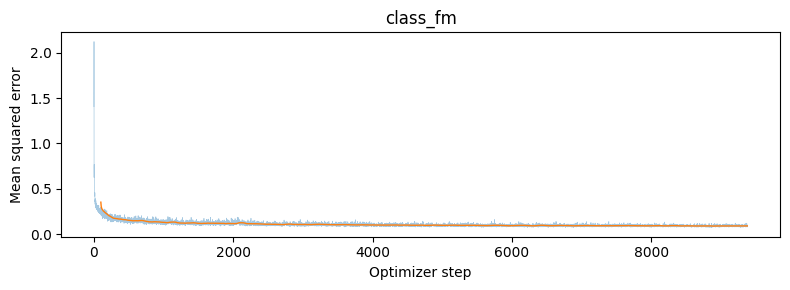

In [ ]:
# results

## 2.6 Sampling from the Class-Conditioned UNet

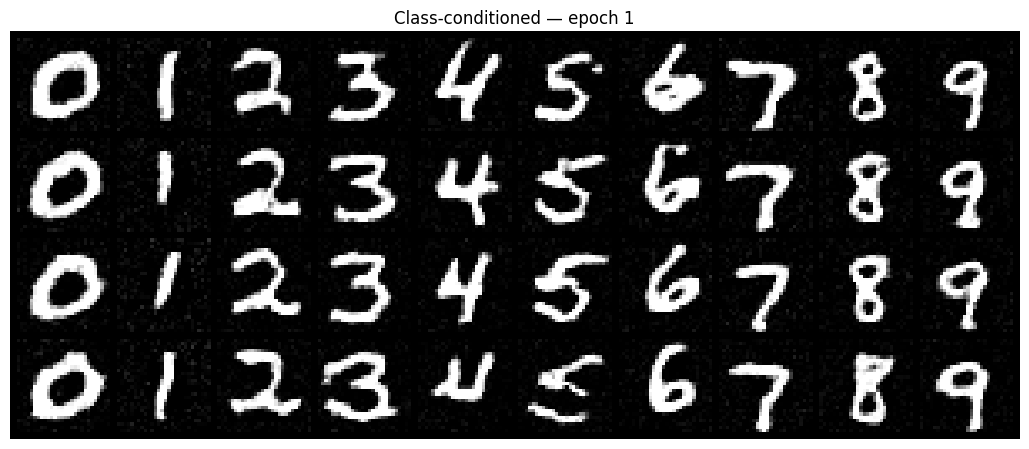

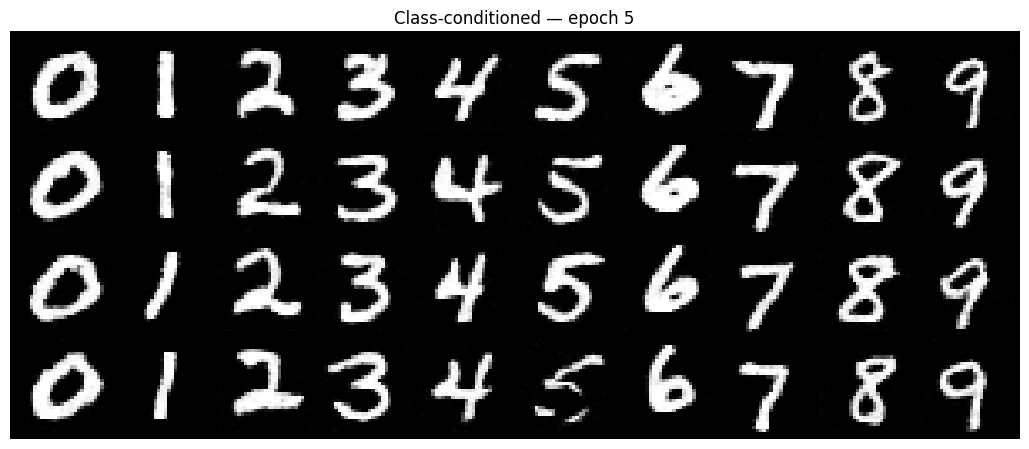

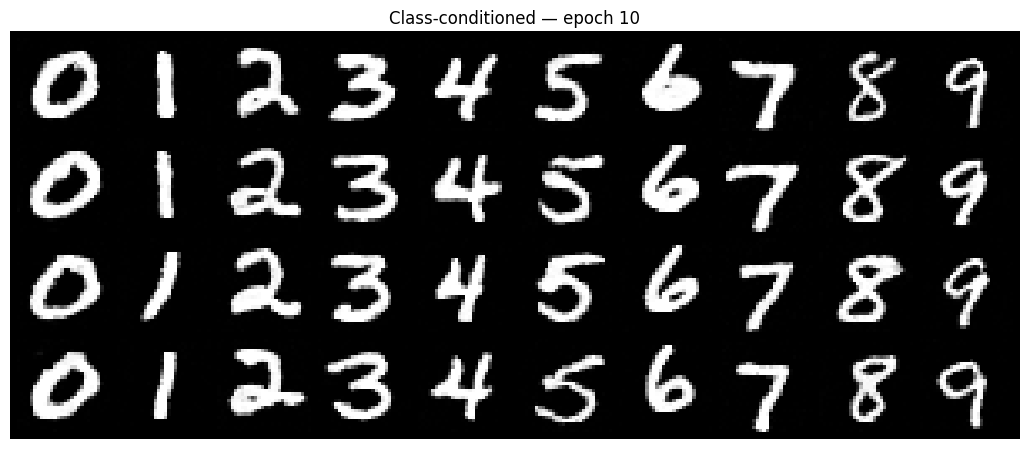

In [ ]:
# results

We sample 4 instances of each digit 0–9 using classifier-free guidance with γ = 5. Each step uses v = v_u + γ(v_c − v_u), with 300 Euler steps from pure noise at t = 0 to a clean image at t = 1. We use the same seed at every checkpoint, so differences between epochs come from training alone.

- **Epoch 1:** The class conditioning is learned almost immediately: every sample is in the requested class, and most are clearly legible. But a few digits are malformed. In the bottom row, the 4 is cropped and the 5 is broken.
- **Epoch 5:** Strokes are smoother and more even. A few weak samples remain, such as the bottom-row 5.
- **Epoch 10:** All 40 samples are clean, well-formed digits. The four samples of each class vary naturally in slant and stroke thickness. The 6 in the top row is slightly overfilled.

### Removing the learning-rate scheduler

With the scheduler, the learning rate decays exponentially from 1e-2 to about 1e-3 over 10 epochs. The high early rate makes fast progress, and the lower late rate lets the model settle into a minimum. Simply deleting the scheduler would keep 1e-2 for the whole run, leaving the optimizer bouncing around a minimum instead of settling into it.

To compensate, I made two changes:
1. **A constant learning rate of 1e-3.** This matches the rate the scheduled run ends at, so the model can settle the same way, at the cost of slower early progress.
2. **Gradient clipping at norm 1.0.** This guards against the loss spikes visible early in the training curve.

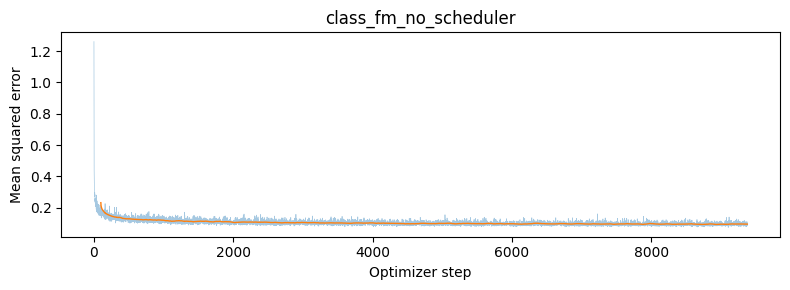

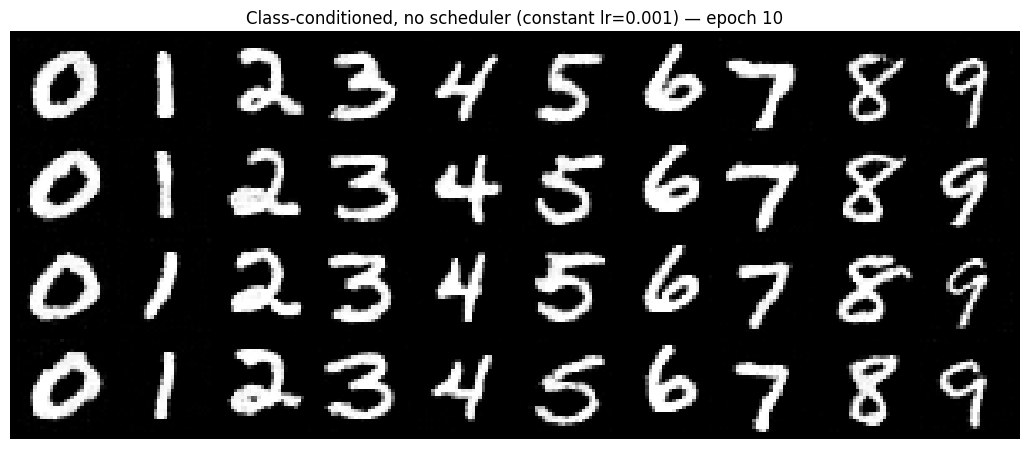

In [ ]:
# results

**Result:** Over the last 100 steps, the average training loss was 0.0946 without the scheduler vs. 0.0918 with it, about 3% higher. The samples are very close in quality: every digit is legible and in the correct class. The no-scheduler digits have slightly bolder, thicker strokes. So similar performance is achievable without a scheduler. The scheduler mainly buys a slightly lower final loss and faster early convergence.